<p align="center">
  <img src="https://www.isae-supaero.fr/wp-content/smush-webp/2026/04/RF-ENAC-ISAE-SUPAERO.png.webp" alt="Logo ENAC ISAE-SUPAERO" width="500">
</p>

<div style="text-align: center; border: 2px solid #2E86C1; padding: 20px; border-radius: 10px; background-color: #FFFFFF;">

# Classification & prédiction de l'évolution de la maladie de Parkinson
### *Analyse prédictive basée sur les données cliniques*

---

**Auteurs :** Sanfilippo Marco | Francine-Habas Mathis

**Institutions :** ENAC | ISAE-SUPAERO | INSA-Toulouse

**Année :** 2026-2027  

**UE :** Apprentissage automatique
</div>

# 1 Introduction et méthodologie

## 1.1 Introduction

Après la maladie d'Alzheimer, la maladie de Parkinson est la deuxième affection neurodégénérative la plus fréquente au monde. En France, on estime qu'environ 200 000 personnes en souffrent. Cette pathologie se caractérise par une perte progressive des neurones dopaminergiques<a href="#note1"><sup>[1]</sup></a>, ce qui entraîne des troubles moteurs et cognitifs invalidants. En raison de la variabilité des symptômes d'un patient à l'autre, anticiper l'évolution clinique de la maladie est difficile. Notons qu'aucun traitement n'a encore fait ses preuves<a href="#note2"><sup>[2]</sup></a>. Actuellement, le suivi de l'évolution de la maladie repose sur le score clinique unifié MDS-UPDRS (*Movement Disorder Society - Unified Parkinson's Disease Rating Scale*). Son évaluation nécessite des examems physiques en laboratoire qui sont longs, coûteux et contraignants pour les patients. L'objectif principal de notre étude est donc d'explorer une méthode permettant dévaluer la progression du handicap à distance, de manière fréquente et non invasive. Notre hypothèse s'appuie sur le fait que la dysphonie contient des biomarquers pertinents. Ce projet vise à concevoir des modèles d'apprentissage automatique pour prédire les composantes du score UPDRS à partir de ces signaux vocaux.

Notre problématique est donc la suivante : Dans quelle mesure les caractéristiques acoustiques de la voix à un instant T permettent-elles de prédire le score UPDRS d'un patient parkinsonien ? Nous commencerons par une phase d'exploration et de *feature engineering*, cela nous permettra de comprendre pourquoi une approche globale n'est pas envisageable. Enfin, nous vous présenterons une solution basée sur les modèles à effets mixtes avant de conclure sur les limites et les perspectives de notre étude.

## 1.2 Choix algorithmiques

Pour modéliser ce problème de prédiction, nous formulerons notre tâche comme un problème de régression supervisée. Une première phase de *feature engineering* est nécessaire. Elle contient la standardisation des variables et l'analyse de la colinéarité, de nombreuses métriques vocales présentant de fortes corrélations intrinsèques.


## 1.3 Le dataset

Le dataset étudié, issu du projet "*Parkinson's Telemonitoring*", est divisé en deux sous-ensembles :

- **`X` (features)** : Ce DataFrame contient les variables explicatives mesurées pour chaque sujet. Ces caractéristiques incluent l'âge, le sexe, le temps de test, ainsi que différentes mesures biométriques vocales.

- **`y` (targets)** : Ce DataFrame contient les variables cibles à prédire. Il s'agit ici des scores cliniques UPDRS :
    - `motor_UPDRS` : évalue spécifiquement la gravité des symptômes moteurs de la maladie.
    - `total_UPDRS` : constitue une mesure globale de la sévérité de la pathologie.

L'échelle MDS-UPDRS se structure en quatre parties distinctes : l'impact des symptômes non moteurs (ex. l'humeur, le sommeil) et moteurs sur la vie quotifienne ; un examem moteur approfondu par un clinicien ; et une évaluation des complications liées aux traitements. Chaque item étant scoré de 0 (normal) à 4 (sévère), cette échelle quantitative permet lister précisément l'évolution du handicap et de mesurer l'efficacité des traitements mis en place.

Ce jeu de données a été spécifiquement constitué à partir d'une cohorte de 42 patients se trouvant à un stade précoce de la maladie de Parkinson. Cette caractéristique fondamentale explique pourquoi les scores de sévérité clinique (UPDRS total) plafonnent autour de 55, loin du maximum théorique de 199 qui caractérise une invalidité totale. La restriction de l'étude à ce stade initial est cruciale pour l'interprétation des analyses : elle homogénéise le niveau de progression de la pathologie et explique l'absence de forte corrélation entre l'âge et la sévérité des symptômes, les patients partageant tous un historique clinique similaire indépendamment de leur âge biologique.

Dans ce jeu de données, chaque ligne représente une observations pour un sujet à un moment donné, chaque patient étant identifié par la colonne `.datas.ids`.

Les caractéristiques extraites de la voix se divisent en trois grandes catégories :
- **Jitter** : Mesure les variations de la période fondamentale de la voix. Une personne saine possède une fréquence vocale relativement stable, tandis qu'un patient atteint de Parkinson présente des micro-fluctuations.
- **Shimmer** : Mesure les variations de l'amplitude d'un cycle sonore à l'autre.
- **Variables non linéaires** : `RPDE`, `DFA` et `PPE` sont des mesures non linéaires et dynamiques permettant de détecter des anomalies que le `Jitter` et le `Shimmer` ne voient pas.

| Caractéristique | Définition |
| --- | --- |
| `age` | L'âge du patient étudié. |
| `test_time` | Temps écoulé depuis l'inclusion dans l'essai clinique. |
| `Jitter(%)` | Pourcentage moyen de variation de la fréquence d'un cycle à l'autre. |
| `Jitter(Abs)` | Variation absolue de la fréquence d'un cycle à l'autre (en secondes). |
| `Jitter:RAP` | La variation absolue de la fréquence sur une moyenne glissante de 3 cycles consécutifs. |
| `Jitter:RAP`| Variation absolue de la fréquence sur une moyenne glissante de 3 cycles consécutifs. |
| `Jitter:PPG5` | Variabilité calculée sur une moyenne glissante de 5 cycles. |
| `Jitter:DDP` | Moyenne des différences absolues entre deux cycles consécutifs. |
| `Shimmer` | Variation moyenne de l'amplitude d'un cycle à l'autre. |
| `Shimmer(dB)` | Variation d'amplitude convertie en décibels. |
| `Shimmer:APQ3` | Variabilité de l'amplitude lissée sur 3 cycles consécutifs. |
| `Shimmer:APQ5` | Variabilité de l'amplitude lissée sur 5 cycles. |
| `Shimmer:APQ11` | Variabilité de l'amplitude lissée sur 11 cycles. |
| `Shimmer:DDA` | Moyenne des différences absolues entre les amplitudes de cycles consécutifs |
| `NHR` | Ratio entre le niveau de bruit et les composantes harmoniques. Une valeur élevée indique une voix plus bruitée. |
| `HNR` | L'inverse du `NHR`. Une valeur faible traduit un enrouement (dysphonie). |
| `RPDE` | Mesure de la régularité et de la périodicité du signal vocal. Une valeur proche de 1 indique un signal typique de la dysphonie parkinsonienne. |
| `DFA` | Analyse de l'auto-similarité à long terme du signal vocal. |
| `PPE` | Mesure de l'entropie de la fréquence de la parole conçue spécifiquement pour la maladie de Parkinson. Elle évalue l'incapacité du patient à maintenir une fréquence stable lors de la prononciation d'une voyelle prolongée. |

--
<p id="note1"><small>[1] : Les neuronnes dopaminergiques sont responsables de la circulation de la dopamine. Or, cette hormone gère le désir ou la motivation. A termes, les patients étant dépourvus de ces neuronnes perdent "le goût à la vie".</small></p>
<p id="note2"><small>[2] : Il est important de noter qu'aucun traitement n'a encore été trouvé pour stopper la progression ou même pour la ralentir. Aujourd'hui, seuls des traitements permettant de compenser le manque de dopamine sont sur le marché. Il s'agit d'un traitement assez lourd, avec des prises quotidiennes de médicaments.</small></p>

# 2 Analyse exhaustive du dataset

## 2.1 Import du dataset

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, LassoCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, classification_report
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import scipy.stats as stats
import warnings

# Uncomment this line for the first use
#!pip install ucimlrepo

# Import dataset
from ucimlrepo import fetch_ucirepo

datas_pks = fetch_ucirepo(id=189)

X = datas_pks.data.features
y = datas_pks.data.targets

X_features = X
y_targets = y

patient_ids = datas_pks.data.ids

#print(datas_pks.metadata)
#print(datas_pks.variables)
#print(datas_pks)

## 2.2 Vérifications du dataset

Il est tout d'abord nécessaire de vérifier la configuration du dataset et d'obtenir des informations sur les données stockées. Au vu des premières analyses, nous pouvons observer qu'aucune donnée n'est manquante  dans les DataFrames `X` et `y`. De plus, toutes les colonnes sont numériques.

In [ ]:
print("First lines of the features (X):\n")
display(X.head())

print("\nInformation on features (X):\n")
X.info()

print("\nFirst lines of the targets (y):\n")
display(y.head())

print("\nInformations on the targets (y):\n")
y.info()

print("\nMissing values ​​in X:\n")
display(X.isnull().sum())

print("\nMissing values ​​in y:\n")
display(y.isnull().sum())

First lines of the features (X):



,age,test_time,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE,sex
0,72,5.6431,0.00662,0.000034,0.00401,0.00317,0.01204,0.02565,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006,0
1,72,12.6660,0.00300,0.000017,0.00132,0.00150,0.00395,0.02024,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810,0
2,72,19.6810,0.00481,0.000025,0.00205,0.00208,0.00616,0.01675,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014,0
3,72,25.6470,0.00528,0.000027,0.00191,0.00264,0.00573,0.02309,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277,0
4,72,33.6420,0.00335,0.000020,0.00093,0.00130,0.00278,0.01703,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361,0



Information on features (X):

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   age            5875 non-null   int64  
 1   test_time      5875 non-null   float64
 2   Jitter(%)      5875 non-null   float64
 3   Jitter(Abs)    5875 non-null   float64
 4   Jitter:RAP     5875 non-null   float64
 5   Jitter:PPQ5    5875 non-null   float64
 6   Jitter:DDP     5875 non-null   float64
 7   Shimmer        5875 non-null   float64
 8   Shimmer(dB)    5875 non-null   float64
 9   Shimmer:APQ3   5875 non-null   float64
 10  Shimmer:APQ5   5875 non-null   float64
 11  Shimmer:APQ11  5875 non-null   float64
 12  Shimmer:DDA    5875 non-null   float64
 13  NHR            5875 non-null   float64
 14  HNR            5875 non-null   float64
 15  RPDE           5875 non-null   float64
 16  DFA            5875 non-null   float64
 17  PPE            5875 n

,motor_UPDRS,total_UPDRS
0,28.199,34.398
1,28.447,34.894
2,28.695,35.389
3,28.905,35.810
4,29.187,36.375



Informations on the targets (y):

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   motor_UPDRS  5875 non-null   float64
 1   total_UPDRS  5875 non-null   float64
dtypes: float64(2)
memory usage: 91.9 KB

Missing values ​​in X:



,0
age,0
test_time,0
Jitter(%),0
Jitter(Abs),0
Jitter:RAP,0
Jitter:PPQ5,0
Jitter:DDP,0
Shimmer,0
Shimmer(dB),0
Shimmer:APQ3,0



Missing values ​​in y:



,0
motor_UPDRS,0
total_UPDRS,0


## 2.3 Analyse univariée

In [ ]:
# Creation of the combined DataFrame and addition of the patient identifier
df_combined = pd.concat([X, y], axis=1)
df_combined['patient_id'] = patient_ids.values
df_patients_uniques = df_combined.drop_duplicates(subset=['patient_id'])

resume_statistique = df_combined.describe().T
display(resume_statistique)

,count,mean,std,min,25%,50%,75%,max
age,5875.0,64.804936,8.821524,36.000000,58.000000,65.000000,72.000000,85.000000
test_time,5875.0,92.863722,53.445602,-4.262500,46.847500,91.523000,138.445000,215.490000
Jitter(%),5875.0,0.006154,0.005624,0.000830,0.003580,0.004900,0.006800,0.099990
Jitter(Abs),5875.0,0.000044,0.000036,0.000002,0.000022,0.000034,0.000053,0.000446
Jitter:RAP,5875.0,0.002987,0.003124,0.000330,0.001580,0.002250,0.003290,0.057540
Jitter:PPQ5,5875.0,0.003277,0.003732,0.000430,0.001820,0.002490,0.003460,0.069560
Jitter:DDP,5875.0,0.008962,0.009371,0.000980,0.004730,0.006750,0.009870,0.172630
Shimmer,5875.0,0.034035,0.025835,0.003060,0.019120,0.027510,0.039750,0.268630
Shimmer(dB),5875.0,0.310960,0.230254,0.026000,0.175000,0.253000,0.365000,2.107000
Shimmer:APQ3,5875.0,0.017156,0.013237,0.001610,0.009280,0.013700,0.020575,0.162670


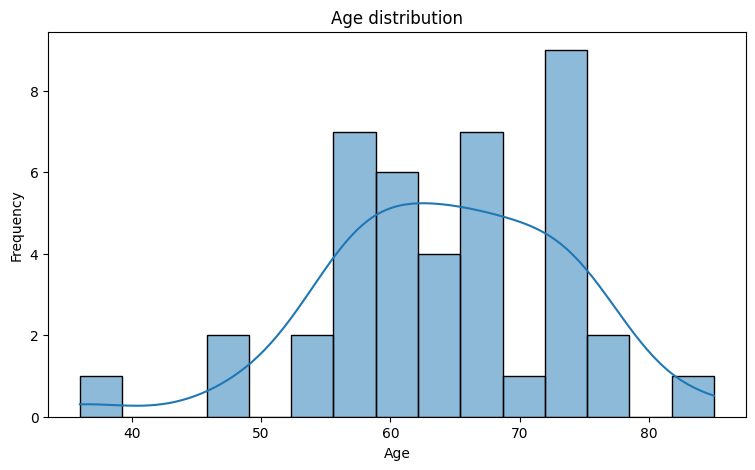

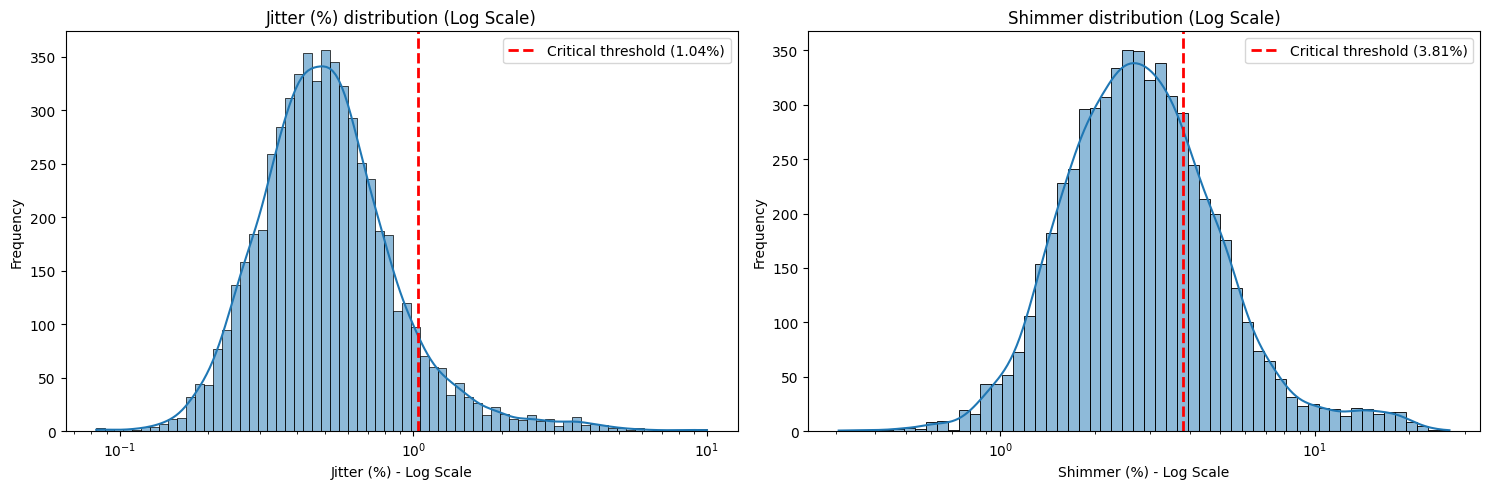

In [ ]:
# Age distribution
plt.figure(figsize=(9, 5))
sns.histplot(df_patients_uniques['age'], kde=True, bins=15)
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Thresholds defined in original percentages
critical_jitter_threshold = 1.04
critical_shimmer_threshold = 3.81

# Jitter & Shimmer distributions
plt.figure(figsize=(15, 5))

# Jitter(%) distribution
ax = plt.subplot(1, 2, 1)
sns.histplot(df_combined['Jitter(%)'] * 100, kde=True, log_scale=True)
plt.axvline(x=critical_jitter_threshold, color='red', linestyle='--', linewidth=2, label=f'Critical threshold ({critical_jitter_threshold}%)')
plt.title("Jitter (%) distribution (Log Scale)")
plt.xlabel("Jitter (%) - Log Scale")
plt.ylabel("Frequency")
plt.legend()

# Shimmer distribution
plt.subplot(1, 2, 2)
sns.histplot(df_combined['Shimmer'] * 100, kde=True, log_scale=True)
plt.axvline(x=critical_shimmer_threshold, color='red', linestyle='--', linewidth=2, label=f'Critical threshold ({critical_shimmer_threshold}%)')
plt.title("Shimmer distribution (Log Scale)")
plt.xlabel("Shimmer (%) - Log Scale")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

**Interprétation :**

L'analyse de la distribution de l'âge confirme une démographie cohérente avec l'épidémiologie classique de la maladie de Parkinson. Bien que la courbe de tendance suggère une moyenne d'âge globale autour de 65 ans, l'histogramme montre que la plus forte concentration de patients se situe dans la tranche des 72 à 75 ans.   La distribution met également en évidence une cohorte étendue, marquée par quelques valeurs extrêmes. On peut observer l'inclusion d'un profil à déclenchement précoce, avec un âge minimum de 36 ans. Cela contraste avec le patient le plus agé qui atteint 85 ans. Cette amplitude des âges soulève une hypothèse pour la suite de l'étude : il conviendra de vérifier si le facteur `age` est significativement corrélé à la sévérité et à la vitesse de progression de la maladie.

L'analyse univariée met en évidence des distributions fortement asymétriques pour les deux mesures vocales. À noter que pour faciliter la lisibilité des visualisations, les valeurs sont affichées en pourcentage, bien qu'elles soient initialement stockées en base 1 dans le dataset original.Concernant la variable `Jitter` (instabilité de la fréquence), la distribution est concentrée autour d'un pic à environ 0,5 %. Cette valeur centrale se situe dans la norme physiologique, le seuil pathologique de base étant généralement fixé à 1 %. Cependant, nous avons des valeurs extrêmes (jusqu'à 10 %) qui illustrent une dégradation importante du contrôle des cordes vocales chez les patients aux stades plus avancés de la maladie. De plus, la dynamique pour la variable `Shimmer` (instabilité de l'amplitude) est identique. La majorité des enregistrements se situent entre 2 % et 3 %, ce qui correspond à une voix saine, sous le seuil clinique habituel de 3,8 % à 5 %. La courbe, très étalée, atteint des valeurs supérieures à 25 %, traduisant une faiblesse vocale et des variations d'amplitude importantes.   Ces distributions écrasées et exprimées dans des ordres de grandeur différents confirment l'absolue nécessité de standardiser les données avant la modélisation. En appliquant le *StandardScaler*, la moyenne de chaque variable sera ramenée à 0 et son écart-type à 1.

Nous pouvons dès lors noter une limite dans notre étude : la grande majorité des patients ne sont qu'à un stade précoce de la maladie. Cela rendra l'analyse et la prédiction plus difficile.

## 2.4 Analyse multivariée

### 2.4.1 Analyse des corrélations

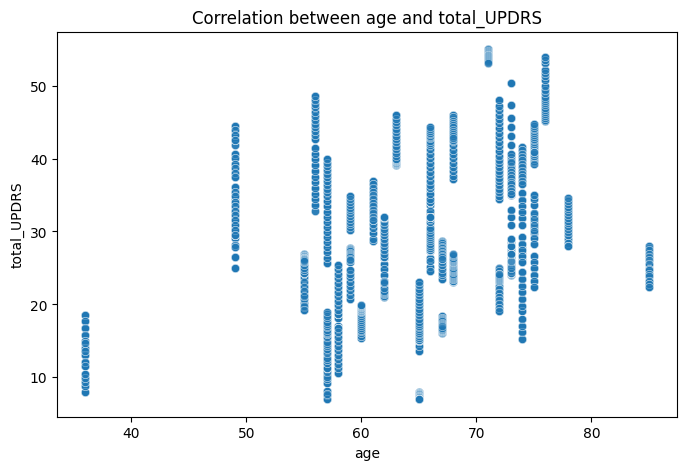

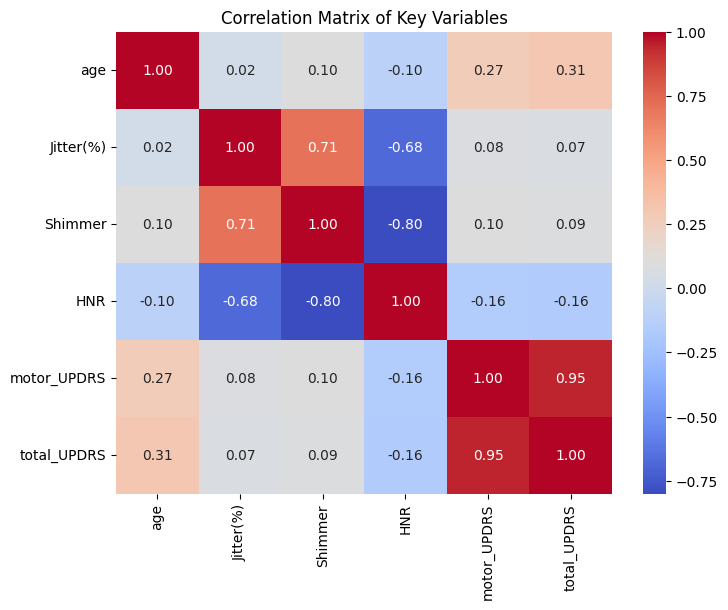

In [ ]:
# Correlation between age and total_UPDRS
plt.figure(figsize=(8, 5))
sns.scatterplot(x='age', y='total_UPDRS', data=df_combined, alpha=0.6)
plt.title("Correlation between age and total_UPDRS")
plt.xlabel("age")
plt.ylabel("total_UPDRS")
plt.show()

# Correlation matrix between some variables
plt.figure(figsize=(8, 6))
correlation_matrix = df_combined[['age', 'Jitter(%)', 'Shimmer', 'HNR', 'motor_UPDRS', 'total_UPDRS']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Key Variables")
plt.show()

**Interprétation :**

Le premier graphique montre la répartition des scores UPDRS totaux selon l'âge. Les lignes verticales représentent les multiples mesures prises pour un même patient au fil du temps. On peut en tirer plusieurs constats. Tout d'abord, les variations du score UPDRS changent beaucoup d'une personne à une autre. Certains patients ont des scores très stables sur la période étudiée, tandis que d'autres fluctuent fortement, indépendamment de l'âge. De plus, L'âge ne semble pas impacter directement la sévérité des symptômes sur ce graphique. Cela peut s'expliquer par le fait que tous les patients sont à un stade encore précoce. Leurs scores plafonnent donc logiquement autour de 55.

Le second graphique analyse les corrélations entre les variables. Dans un premier temps, les variables `motor_UPDRS` et `total_UPDRS` sont très corrélées. L'aspect moteur représente la majeure partie su score global, prédire l'un ou l'autre donnera un résultat très similaire. De plus, les indicateurs de voix sont très liés entre eux. Cette répétition d'informations justifie l'utilisation d'une méthode de synthèse avant l'apprentissage du modèle. Les variables vocales prises isolément ont très peu de lien directe avec les scores UPDRS. Une simple régression linéaire ne fonctionnera pas, il faudra utiliser des algorithmes capables de trouver des relations plus complexes.

### 2.4.2 Évolution temporelle individuelle du score UPDRS

Afin d'analyser la progression de la maladie, nous traçons l'évolution du score `total_UPDRS` en fonction du temps (`test_time`) pour plusieurs patients. L'objectif est d'observer la variabilité des trajectoires individuelles.

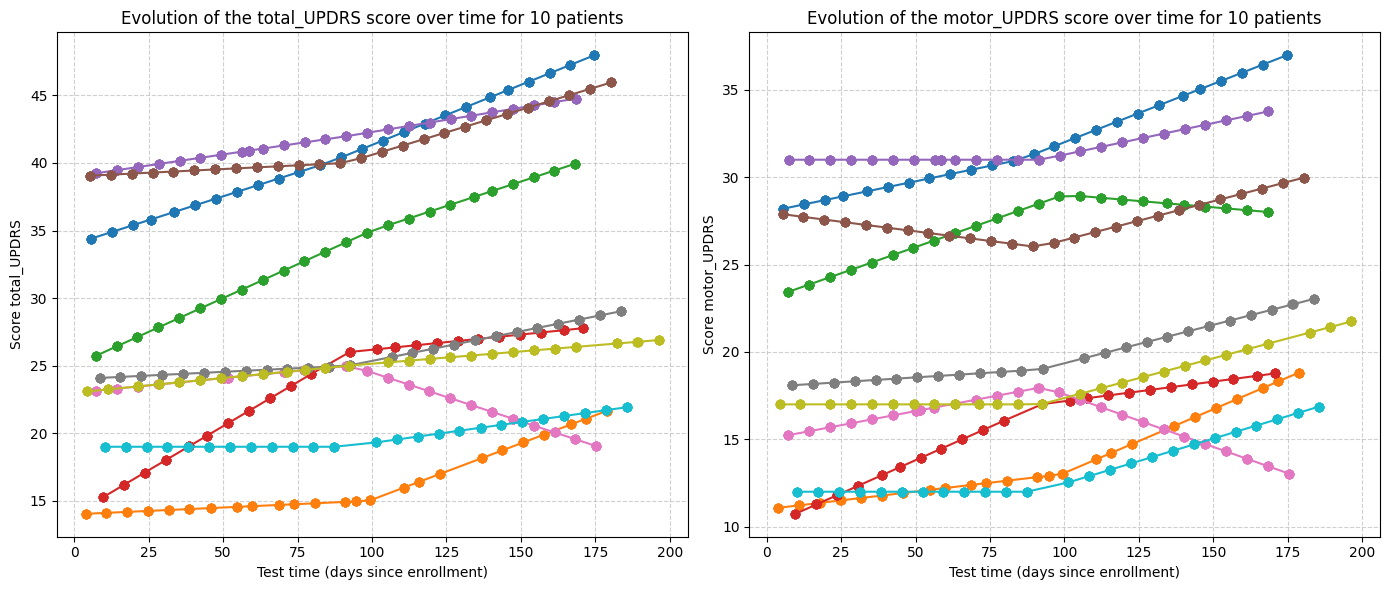

In [ ]:
nb_patient_to_test = 10
unique_ids = df_combined['patient_id'].unique() # We retrieve the patient's unique identifiers
patients_to_plot = unique_ids[:nb_patient_to_test]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# total_UPDRS display
for patient in patients_to_plot:
    patient_data = (df_combined[df_combined['patient_id'] == patient].sort_values(by='test_time'))
    axes[0].plot(patient_data['test_time'], patient_data['total_UPDRS'], marker='o', label=f'Patient {patient}')

axes[0].set_title(f"Evolution of the total_UPDRS score over time for {nb_patient_to_test} patients")
axes[0].set_xlabel("Test time (days since enrollment)")
axes[0].set_ylabel("Score total_UPDRS")
axes[0].grid(True, linestyle='--', alpha=0.6)
#axes[0].legend()

# motor_UPDRS display
for patient in patients_to_plot:
    patient_data = (df_combined[df_combined['patient_id'] == patient].sort_values(by='test_time'))
    axes[1].plot(patient_data['test_time'], patient_data['motor_UPDRS'], marker='o', label=f'Patient {patient}')

axes[1].set_title(f"Evolution of the motor_UPDRS score over time for {nb_patient_to_test} patients")
axes[1].set_xlabel("Test time (days since enrollment)")
axes[1].set_ylabel("Score motor_UPDRS")
axes[1].grid(True, linestyle='--', alpha=0.6)
#axes[1].legend()

plt.tight_layout()
plt.show()

**Interprétation :**

Ces deux graphiques illustrent le suivi de 10 patients sur une période d'environ six mois. L'analyse de ces trajectoires met en évidence plusieurs points clés.

Tout d'abord, nous pouvons remarquer une certaine tendance à l'aggravation. Pour la majorité des patients, les scores augmentent progressivement ce qui reflète l'évolution habituelle des symptômes de cette maladie. Toutefois, la vitesse de progression varie d'un individu à l'autre. Il serait donc intéressant d'utiliser des méthodes de clustering pour identifier des profils distints.

De plus, bien que la tendance générale soit à la hausse, certains patients montrent une légère diminution de leurs sores sur certaines périodes. Cela peut s'expliquer par différents facteurs comme l'ajustement thérapeutique. Notons tout de même que cette diminution n'intervient qu'environ 100 jours après le début de l'expérimentation.

Enfin, graphiquement, nous pouvons confirmer la forte corrélation, déjà identifiée dans la matrice des corrélations, entre les variables `total_UPDRS` et `motor_UPDRS`. Ce résultat est cohérent puisque l'une est faite de l'autre.

### 2.4.3 Clustering linéaire des trajectoires individuelles

Pour visualiser des tendances claires, nous modélisons la trajectoire de chaque patient par une réression linéaire simple de la forme :

$$y=ax+b$$

Où :
- y = `total_UPDRS` ;
- a = `pente` ;
- x = `test_time` ;
- b = `intercept`.

Maintenant que toutes les droites sont de la même forme, nous pouvons utilise un algorithme de clustering $K$-Means pour identifier les différentes tendances de progression de la maladie.

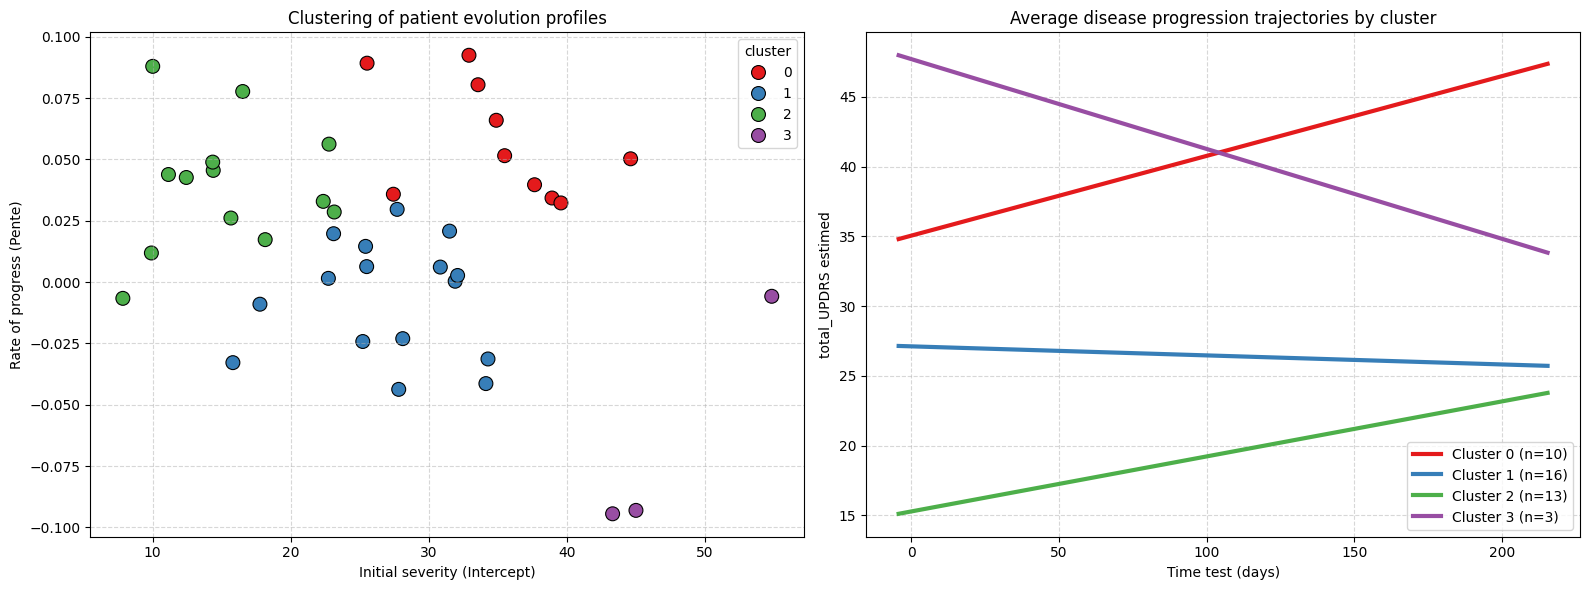

In [ ]:
patient_profiles = [] # Contains all the patients
unique_patients = df_combined['patient_id'].unique()

for patient in unique_patients:
    patient_data = df_combined[df_combined['patient_id'] == patient]
    X_p = patient_data[['test_time']].values
    y_p = patient_data['total_UPDRS'].values
    reg = LinearRegression().fit(X_p, y_p)
    patient_profiles.append({'patient_id': patient, 'intercept': reg.intercept_, 'slope': reg.coef_[0]})

df_profiles = pd.DataFrame(patient_profiles)

# Clustering
features_clustering = df_profiles[['intercept', 'slope']]
scaler_clust = StandardScaler() # Standardization
features_scaled = scaler_clust.fit_transform(features_clustering)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_profiles['cluster'] = kmeans.fit_predict(features_scaled)

# Merge cluster information into the main DataFrame
df_combined = df_combined.merge(df_profiles[['patient_id', 'cluster']], on='patient_id', how='left')

# Display
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

unique_clusters = sorted(df_profiles['cluster'].unique())
colors = sns.color_palette('Set1', n_colors=len(unique_clusters))
cluster_color_map = {cluster_id: colors[i] for i, cluster_id in enumerate(unique_clusters)}
sns.scatterplot(x='intercept', y='slope', hue='cluster', data=df_profiles, palette=cluster_color_map, s=100, ax=axes[0], edgecolor='k')
axes[0].set_title("Clustering of patient evolution profiles")
axes[0].set_xlabel("Initial severity (Intercept)")
axes[0].set_ylabel("Rate of progress (Pente)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Evolution of resources by cluster
time_grid = np.linspace(df_combined['test_time'].min(), df_combined['test_time'].max(), 100)

for cluster_id in unique_clusters:
    cluster_data = df_profiles[df_profiles['cluster'] == cluster_id]
    mean_intercept = cluster_data['intercept'].mean()
    mean_slope = cluster_data['slope'].mean()
    mean_trajectory = mean_slope * time_grid + mean_intercept # Calculation of the average line for this cluster
    axes[1].plot(time_grid, mean_trajectory, label=f'Cluster {cluster_id} (n={len(cluster_data)})', color=cluster_color_map[cluster_id], linewidth=3)

axes[1].set_title("Average disease progression trajectories by cluster")
axes[1].set_xlabel("Time test (days)")
axes[1].set_ylabel("total_UPDRS estimed")
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

**Interprétation :**

Comme nous nous y attendions, le clustering linéaire n'est pas efficace et représentatif. Nous pouvons remarquer par exemple qu'une classe ne contient que 3 patients. Il serait donc intéressant de faire du clustering quadratique pour obtenir des classes plus homogènes et représentatives.

### 2.4.4 Clustering quadratique des trajectoires individuelles

Bien que l'approximation linéaire offre une première vue d'ensemble, l'évolution de la maladie de Parkinson présente souvent des phases non linéaires. Pour combler ce problème, nous ajustons maintenant un modèle de régression polynomiale pour chaque patient :

$$y = a \cdot t^2 + b \cdot t + c$$

Où :
* $c$ représente la sévérité initiale (*intercept*).
* $b$ représente la vitesse d'évolution initiale.
* $a$ représente l'accélération ou la décélération de la progression.

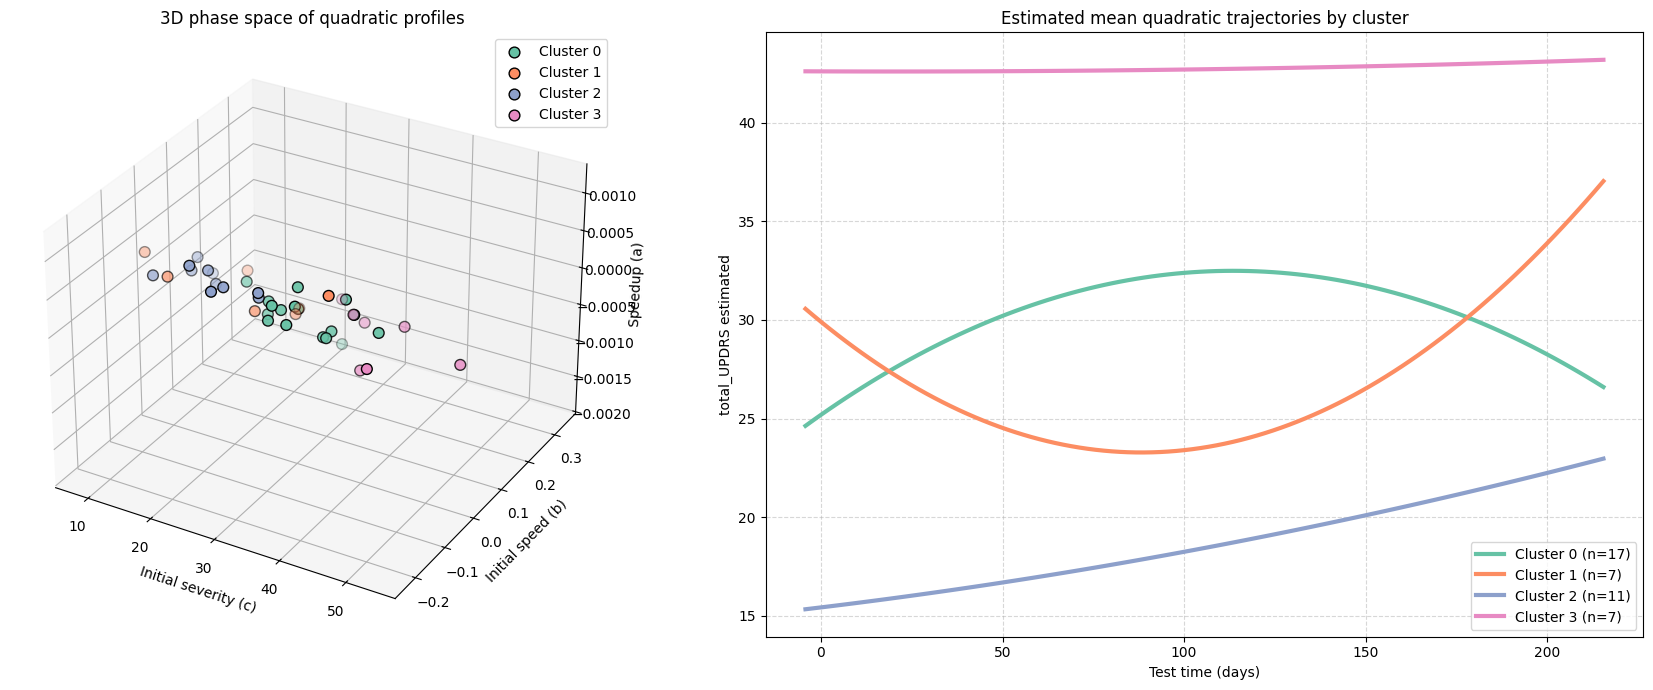

In [ ]:
patient_poly_profiles = []
unique_patients = df_combined['patient_id'].unique()

for patient in unique_patients:
    patient_data = df_combined[df_combined['patient_id'] == patient].sort_values(by='test_time')
    t = patient_data['test_time'].values
    y_p = patient_data['total_UPDRS'].values
    coefs = np.polyfit(t, y_p, 2)
    patient_poly_profiles.append({'patient_id': patient, 'acceleration_a': coefs[0], 'velocity_b': coefs[1], 'intercept_c': coefs[2]})
df_poly_profiles = pd.DataFrame(patient_poly_profiles)

# Standardization of the three characteristics for clustering
features_poly = df_poly_profiles[['acceleration_a', 'velocity_b', 'intercept_c']]
scaler_poly = StandardScaler()
features_poly_scaled = scaler_poly.fit_transform(features_poly)

# Clustering K-Means
kmeans_poly = KMeans(n_clusters=4, random_state=42, n_init=10)
df_poly_profiles['cluster'] = kmeans_poly.fit_predict(features_poly_scaled)

# Merging of trajectory clusters
if 'cluster_poly' in df_combined.columns:
    df_combined = df_combined.drop(columns=['cluster_poly'])

df_combined = df_combined.merge(df_poly_profiles[['patient_id', 'cluster']].rename(columns={'cluster': 'cluster_poly'}), on='patient_id', how='left')

# Display
fig = plt.figure(figsize=(18, 7))

unique_poly_clusters = sorted(df_poly_profiles['cluster'].unique())
poly_colors = sns.color_palette('Set2', n_colors=len(unique_poly_clusters))
poly_cluster_color_map = {c_id: poly_colors[i] for i, c_id in enumerate(unique_poly_clusters)}

ax_3d = fig.add_subplot(1, 2, 1, projection='3d')
for cluster_id in unique_poly_clusters:
    clust_subset = df_poly_profiles[df_poly_profiles['cluster'] == cluster_id]
    ax_3d.scatter(clust_subset['intercept_c'], clust_subset['velocity_b'], clust_subset['acceleration_a'], label=f'Cluster {cluster_id}', color=poly_cluster_color_map[cluster_id], s=60, edgecolor='k')
ax_3d.set_title("3D phase space of quadratic profiles")
ax_3d.set_xlabel("Initial severity (c)")
ax_3d.set_ylabel("Initial speed (b)")
ax_3d.set_zlabel("Speedup (a)")
ax_3d.legend()

ax_traj = fig.add_subplot(1, 2, 2)
time_grid = np.linspace(df_combined['test_time'].min(), df_combined['test_time'].max(), 100)

for cluster_id in unique_poly_clusters:
    clust_subset = df_poly_profiles[df_poly_profiles['cluster'] == cluster_id]
    mean_a = clust_subset['acceleration_a'].mean()
    mean_b = clust_subset['velocity_b'].mean()
    mean_c = clust_subset['intercept_c'].mean()
    mean_curve = mean_a * (time_grid**2) + mean_b * time_grid + mean_c
    ax_traj.plot(time_grid, mean_curve, label=f'Cluster {cluster_id} (n={len(clust_subset)})', color=poly_cluster_color_map[cluster_id], linewidth=3)
ax_traj.set_title("Estimated mean quadratic trajectories by cluster")
ax_traj.set_xlabel("Test time (days)")
ax_traj.set_ylabel("total_UPDRS estimated")
ax_traj.grid(True, linestyle='--', alpha=0.5)
ax_traj.legend()

plt.tight_layout()
plt.show()

**Interprétation :**

L'espace de phase 3D et les trajectoires paraboliques confirment la nature non-linéaire de la progression de la maladie pour une grande partie des patients. Les clusters sont davantage représentatifs de la polution. Cela justifie l'intérêt d'utiliser des algorithmes capablent d'interpreter ces courbes non linéaires.

# 3 Préparation du dataset

## 3.1 Partitionnement et standardisation

Pour garantir l'absence de *data leakage*, nous partitionnons nos données de façon à ce qu'aucun patient présent dans l'ensemble d'entraînement ne se retrouve dans l'ensemble de test.

Pour éviter ce problème, nous allons donc :
1. Transformer les données vocales avec le logarithme pour corriger les distributions des varibles ;
2. Séparer notre DataFrame `X` en ensembles d'entraînement/validation et de test final avec `GroupKFold` ;
3. Standardiser notre ensemble d'entraînement via `sklearn` ;
4. Appliquer la standardisation sur les autres ensembles.

In [ ]:
# Log
skewed_cols = [col for col in df_combined.columns if 'Jitter' in col or 'Shimmer' in col]

# Applying log(1+x) to reduce skewness
for col in skewed_cols:
    df_combined[col] = np.log1p(df_combined[col])

# Preparation of source data
X_features = X.copy()
y_targets = y.copy()
groups = patient_ids.values.flatten() # 1 x n

# Separation (85% - 15%)
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_val_idx, test_idx = next(gss.split(X_features, y_targets, groups))

# Creation of the DataFrames
X_train_val_raw = X_features.iloc[train_val_idx]
y_train_val = y_targets.iloc[train_val_idx]
groups_train_val = groups[train_val_idx]

X_test_final_raw = X_features.iloc[test_idx]
y_test_final = y_targets.iloc[test_idx]
groups_test_final = groups[test_idx]

# Standardisation
scaler = StandardScaler()

# We fit only on te train
X_train_val = pd.DataFrame(scaler.fit_transform(X_train_val_raw), columns=X_features.columns, index=X_train_val_raw.index)
X_test_final = pd.DataFrame(scaler.transform(X_test_final_raw), columns=X_features.columns, index=X_test_final_raw.index)

# We set 5 folds
group_kfold = GroupKFold(n_splits=5)

print(f"Total patients       : {len(np.unique(groups))}")
print(f"Patients in Train/Val: {len(np.unique(groups_train_val))}")
print(f"Patients in Test     : {len(np.unique(groups_test_final))}\n")

print(f"X_train_val dimension : {X_train_val.shape}")
print(f"X_test_final dimension: {X_test_final.shape}")

Total patients       : 42
Patients in Train/Val: 35
Patients in Test     : 7

X_train_val dimension : (4896, 19)
X_test_final dimension: (979, 19)


## 3.2 Analyse en composantes principales

Pour réaliser l'ACP, nous allons :
* Séparer le DataFrame entre les variables catégorielles (`age`, `sexe`, `test_time`) pour réaliser l'ACP uniquement sur les variables utiles.
* Entraîner l'ACP uniquement sur les données d'entraînement et validation standardisées.
* Nous appliquerons ensuite la projection sur `X_validation_final` et sur `X_test_final` de manière indépendante.

Au vu de l'histogramme, et sachant que les données sont très bruitées, nous retiendrons les 8 premières composantes car elles permettent d'expliquer 99 % de la variance du modèle.

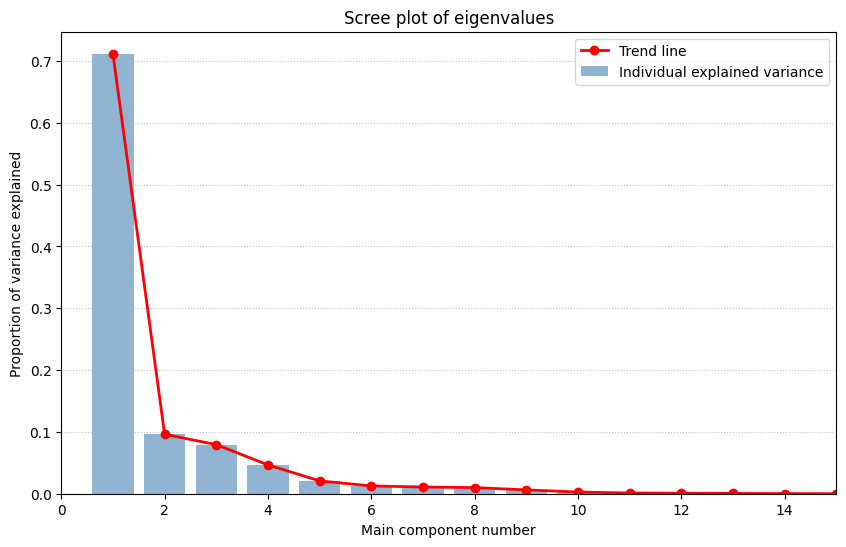

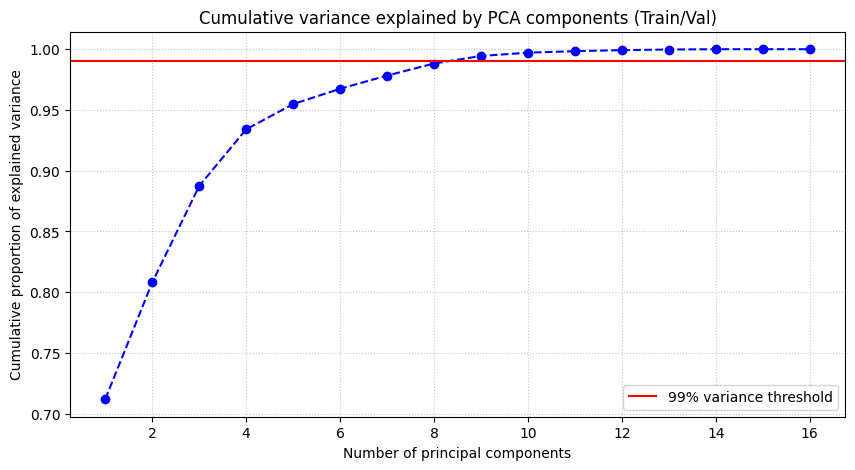

Original vocal variables before PCA : 16
Selected principal components (99%) : 9
Final total dimension Train/Val     : 12
Total final dimension test          : 12
Total variance retained on the voice: 99.44%


In [ ]:
# Identification of columns to exclude from and include in the PCA
cols_to_exclude = ['age', 'sex', 'test_time']
cols_for_pca = [col for col in X_train_val.columns if col not in cols_to_exclude]

# Creation of the subsets
X_train_pca_input = X_train_val[cols_for_pca]
X_test_pca_input = X_test_final[cols_for_pca]

# Trained solely on the vocal variables of the train_val set
pca_explore = PCA(random_state=42)
pca_explore.fit(X_train_pca_input)

variance_individuelle = pca_explore.explained_variance_ratio_
variance_cumulated = np.cumsum(variance_individuelle)

# Display
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(variance_individuelle) + 1), variance_individuelle,
        alpha=0.6, color='steelblue', label='Individual explained variance')
plt.plot(range(1, len(variance_individuelle) + 1), variance_individuelle,
         marker='o', color='red', linewidth=2, label='Trend line')
plt.title('Scree plot of eigenvalues')
plt.xlabel('Main component number')
plt.ylabel('Proportion of variance explained')
plt.xlim(0, 15)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.legend()
plt.show()

# Display
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(variance_cumulated) + 1), variance_cumulated, marker='o', linestyle='--', color='b')
plt.axhline(y=0.99, color='r', linestyle='-', label='99% variance threshold')
plt.title('Cumulative variance explained by PCA components (Train/Val)')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative proportion of explained variance')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

# We want 95% of the variance
pca = PCA(n_components=0.99, random_state=42)

# Fit & transform on the train set
train_pca_features = pca.fit_transform(X_train_pca_input)

# Transform on the test set
test_pca_features = pca.transform(X_test_pca_input)

train_pca_df = pd.DataFrame(train_pca_features, index=X_train_val.index,
                            columns=[f'PC{i+1}' for i in range(train_pca_features.shape[1])])
test_pca_df = pd.DataFrame(test_pca_features, index=X_test_final.index,
                           columns=[f'PC{i+1}' for i in range(test_pca_features.shape[1])])

# The variables are concatenated with the removed variables
X_train_final_pca = pd.concat([X_train_val[cols_to_exclude], train_pca_df], axis=1)
X_test_final_pca = pd.concat([X_test_final[cols_to_exclude], test_pca_df], axis=1)

# Display
print(f"Original vocal variables before PCA : {X_train_pca_input.shape[1]}")
print(f"Selected principal components (99%) : {pca.n_components_}")
print(f"Final total dimension Train/Val     : {X_train_final_pca.shape[1]}")
print(f"Total final dimension test          : {X_test_final_pca.shape[1]}")
print(f"Total variance retained on the voice: {np.sum(pca.explained_variance_ratio_):.2%}")

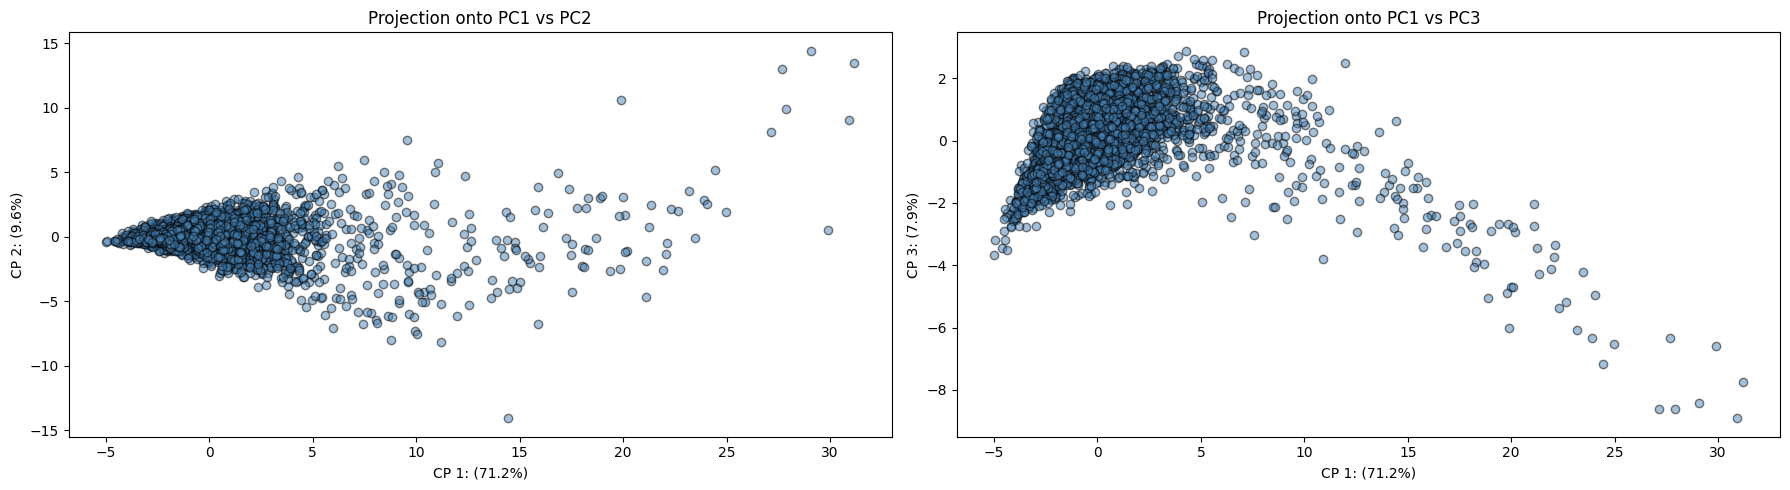

In [ ]:
# Retrieving the percentages of explained variance for each component
var_expl = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# PC1 vs PC2
axes[0].scatter(train_pca_features[:, 0], train_pca_features[:, 1], alpha=0.5, edgecolor='k', c='steelblue')
axes[0].set_xlabel(f'CP 1: ({var_expl[0]:.1%})')
axes[0].set_ylabel(f'CP 2: ({var_expl[1]:.1%})')
axes[0].set_title('Projection onto PC1 vs PC2')

# PC1 vs PC3
axes[1].scatter(train_pca_features[:, 0], train_pca_features[:, 2], alpha=0.5, edgecolor='k', c='steelblue')
axes[1].set_xlabel(f'CP 1: ({var_expl[0]:.1%})')
axes[1].set_ylabel(f'CP 3: ({var_expl[2]:.1%})')
axes[1].set_title('Projection onto PC1 vs PC3')

plt.tight_layout()
plt.show()

In [ ]:
# Retrieval of the weights for each original variable for each principal component
poids_pca = pd.DataFrame(
    pca.components_,
    columns=X_train_pca_input.columns,
    index=[f'PC{i+1}' for i in range(pca.n_components_)]
)

# Display of the 5 original variables with the greatest influence on the first 3 components
for pc in ['PC1', 'PC2', 'PC3']:
    top_variables = poids_pca.loc[pc].abs().sort_values(ascending=False).head(5)

    print(f"{pc} is primarily defined by:")
    for var, abs_weight in top_variables.items():
        vrai_poids = poids_pca.loc[pc, var]
        print(f"  * {var} : {vrai_poids:.3f}")

PC1 is primarily defined by:
  * Shimmer(dB) : 0.278
  * Shimmer : 0.278
  * Shimmer:APQ5 : 0.275
  * Shimmer:APQ3 : 0.269
  * Shimmer:DDA : 0.269
PC2 is primarily defined by:
  * Jitter:DDP : 0.321
  * Jitter:RAP : 0.321
  * Jitter(%) : 0.306
  * Shimmer:DDA : -0.291
  * Shimmer:APQ3 : -0.291
PC3 is primarily defined by:
  * DFA : 0.654
  * RPDE : 0.420
  * PPE : 0.293
  * HNR : -0.286
  * NHR : -0.248


**Interprétation :**

Notons que PC1 regroupe les variations d'intensité et de volume de la voix. PC2 capture la fréquence du son. Tandis que PC3 rassemble les mesures acoustiques plus complexes ainsi que le bruit dans la voix.

Les trois premières composantes contiennent 88,7 % de l'information totale. Dans le premier graphique, nous pouvons constater que les voix stables sont regroupées à gauche. Plus nous allons vers la droite, plus les points s'écartent, ce qui montre des voix plus altérées. Dans le second graphique, la courbure indique des liens non linéaires entre les mesures vocales. Cela confirme le choix d'utiliser des modèles capables de gérer la non-linéarité (ex. RandomForest).



# 4 Le modèle d'apprentissage automatique

Pour l'évaluation de nos métriques, nous avons choisi le R². Il offre une échelle en pourcentage, qui est directement comparable avec un autre R². De plus, il mesure la valeur ajoutée de la voix par rapport à une simple prédiction de la moyenne de la population. Enfin, il signal directement quand un modèle fait pire qu'une estimation constante.

## 4.1 Régression linéaire régularisée

In [ ]:
# First of all, we want to predict total_UPDRS
y_train_target = y_train_val['total_UPDRS']
y_test_target = y_test_final['total_UPDRS']

# Initiation
ridge_model = Ridge(random_state=42)

# Definition of the parameters we attempted to use
param_grid_ridge = {
    'alpha': [0.1, 1.0, 10.0, 50.0, 100.0, 200.0]
}

# Search with cross-validation
grid_search_ridge = GridSearchCV(
    estimator=ridge_model,
    param_grid=param_grid_ridge,
    cv=group_kfold,
    scoring='neg_mean_squared_error', # We want to minimisze the MSE
    n_jobs=-1,
    verbose=1
)

# We fit the model
print(f"Ridge training:")
grid_search_ridge.fit(X_train_final_pca, y_train_target, groups=groups_train_val)

# Extraction of the best results
best_ridge = grid_search_ridge.best_estimator_
best_alpha = grid_search_ridge.best_params_['alpha']
best_cv_rmse = np.sqrt(-grid_search_ridge.best_score_)

print("\nRidge results :")
print(f"Best alpha    : {best_alpha}")
print(f"RMSE          : {best_cv_rmse:.2f}")

# Test
y_pred_ridge = best_ridge.predict(X_test_final_pca)

# Calculation of performance
test_rmse_ridge = np.sqrt(mean_squared_error(y_test_target, y_pred_ridge))
test_r2_ridge = r2_score(y_test_target, y_pred_ridge)

print("\nTest set performance :")
print(f"RMSE                 : {test_rmse_ridge:.2f}")
print(f"R2                   : {test_r2_ridge:.4f}")

Ridge training:
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Ridge results :
Best alpha    : 200.0
RMSE          : 11.69

Test set performance :
RMSE                 : 9.58
R2                   : -0.0928


**Interprétation :**

Le score R² négatif montre que le modèle linéaire fait moins bien qu'une simple prédiction basée sur la moyenne des scores. De plus, le choix de l'hyperparametre le plus élevé de la grille indique que le modèle a dû fortement brider ses coefficients pour éviter d'overfitter sur le bruit des données. Concernant la RMSE, elle est bien trop élevée pour permettre un télémonitoring faible.

Comme nous l'avions conjecturé, la relation entre les composantes vocales et le score UPDRS n'est pas linéaire. Ce résultat pose la *baseline* et justifie le passage à de modèles non linéaires.

## 4.2 Régressions non linéaires

### 4.2.1 Random Forest sur toutes les *features*

In [ ]:
# Initiation
rf_model = RandomForestRegressor(random_state=42)

# Same as before
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid_search_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    cv=group_kfold,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

# We fit
print("Random Forest training:")
grid_search_rf.fit(X_train_final_pca, y_train_target, groups=groups_train_val)

best_rf = grid_search_rf.best_estimator_
best_cv_rmse_rf = np.sqrt(-grid_search_rf.best_score_)

print("\nRandom Forest results :")
print(f"Best parameters       : {grid_search_rf.best_params_}")
print(f"RMSE                  : {best_cv_rmse_rf:.2f}")

# We evaluate the model on the test set
y_pred_rf = best_rf.predict(X_test_final_pca)

test_rmse_rf = np.sqrt(mean_squared_error(y_test_target, y_pred_rf))
test_r2_rf = r2_score(y_test_target, y_pred_rf)

print("\nTest set performance :")
print(f"RMSE                 : {test_rmse_rf:.2f}")
print(f"R2                   : {test_r2_rf:.4f}")

Random Forest training:
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Random Forest results :
Best parameters       : {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 50}
RMSE                  : 13.84

Test set performance :
RMSE                 : 12.70
R2                   : -0.9207


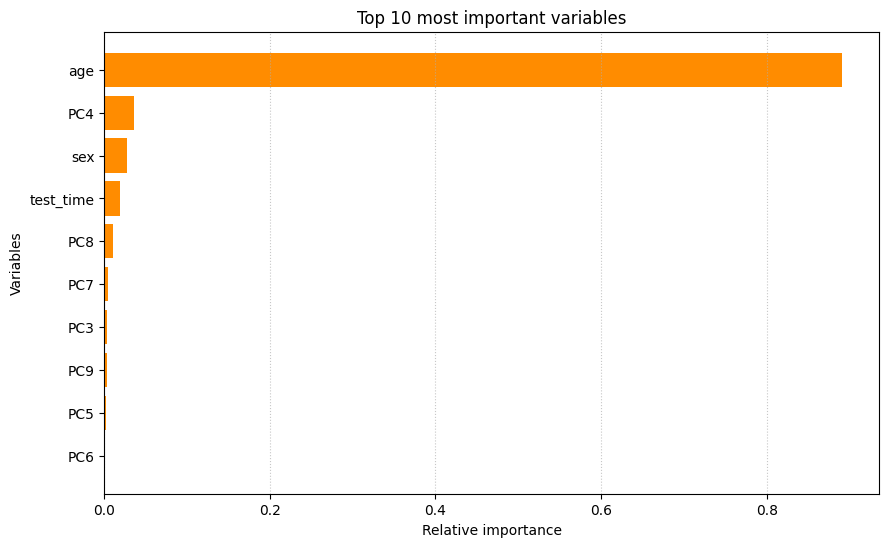

In [ ]:
# Extracting variable importance
importances = best_rf.feature_importances_
features = X_train_final_pca.columns

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'][:10][::-1], importance_df['Importance'][:10][::-1], color='darkorange')
plt.title('Top 10 most important variables')
plt.xlabel('Relative importance')
plt.ylabel('Variables')
plt.grid(axis='x', linestyle=':', alpha=0.7)
plt.show()

**Interprétation :**

Au niveau des performances, malgré la gestion de la non linéarité et l'utilisation d'arbres moins profonds, le modèle échoue sur les patients de test. Le graphique attribue près de 90 % du poids à la variable `age`. Les autres composantes sont complétement ignorées. De la même façon, nous pouvons noter un biais lors de l'apprentissage. L'algorithme prend un raccourci en prédisant le score UPDRS presque exclusivement à partir de l'âge du patient. Ce biais empêche le modèle d'apprendre la signature de la maladie et détruit sa capacité de généralisation.

Nous allons donc essayer d'isoler l'âge en entraînant le modèle uniquement sur la voix. Cela permettra d'évaluer la réelle contribution des marqueurs vocaux.

### 4.2.2 Random Forest sur les variables vocales brutes


 Fit RF

 Test
RMSE : 7.64
R2 : -0.0288


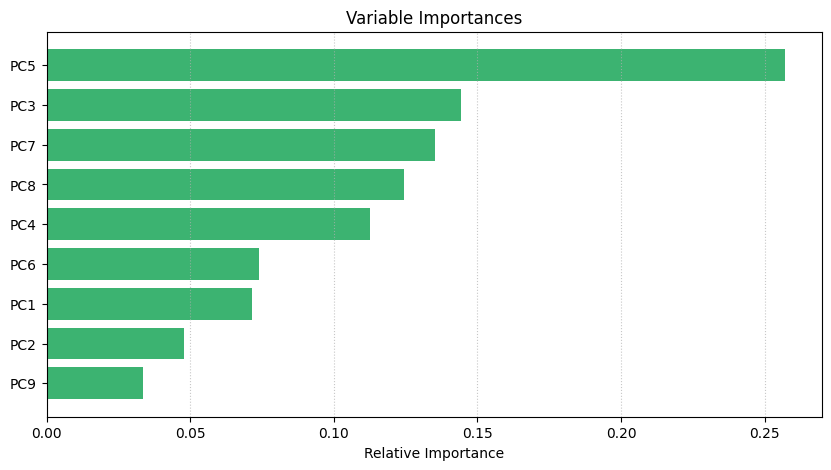

In [ ]:
y_train_target = y_train_val['motor_UPDRS']
y_test_target = y_test_final['motor_UPDRS']

# Isolate vocal variables
vocal_cols = [col for col in X_train_final_pca.columns if col.startswith('PC')]

X_train_vocal = X_train_final_pca[vocal_cols]
X_test_vocal = X_test_final_pca[vocal_cols]

# Fit
print("\n Fit RF")
grid_search_rf_vocal = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=group_kfold,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_search_rf_vocal.fit(X_train_vocal, y_train_target, groups=groups_train_val)
best_rf_vocal = grid_search_rf_vocal.best_estimator_

# Assessment of actual voice performance
y_pred_rf_vocal = best_rf_vocal.predict(X_test_vocal)
test_rmse_vocal = np.sqrt(mean_squared_error(y_test_target, y_pred_rf_vocal))
test_r2_vocal = r2_score(y_test_target, y_pred_rf_vocal)

print("\n Test")
print(f"RMSE : {test_rmse_vocal:.2f}")
print(f"R2 : {test_r2_vocal:.4f}")

importance_vocal_df = pd.DataFrame({
    'Feature': vocal_cols,
    'Importance': best_rf_vocal.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(importance_vocal_df['Feature'][:10][::-1], importance_vocal_df['Importance'][:10][::-1], color='mediumseagreen')
plt.title('Variable Importances')
plt.xlabel('Relative Importance')
plt.grid(axis='x', linestyle=':', alpha=0.7)
plt.show()

**Interprétation :**

Même sans variables démographiques, le modèle échoue encore. Cela met en évidence une limite : la variabilité de la voix entre individus est trop forte pour prédire le score UPDRS absolu. Le modèle exploite désormais l'ensemble de la voix, mais juge les composantes `PC5`, `PC3` et `PC7` plus importantes que `PC1` et `PC2`. Cela semble nous contre-intuitif puisque `PC1` concentre plus de 70 % de la variance des données.

### 4.2.3 Random Forest sur les variables vocales brutes (Sans ACP)

Pour vérifier si l'ACP a dégradé les performances du Random Forest, nous allons maintenant entraîner le même modèle directement sur les variables vocales brutes standardisées, sans appliquer de réduction de dimension.

In [ ]:
y_train_target = y_train_val['motor_UPDRS']
y_test_target = y_test_final['motor_UPDRS']

vocal_cols_raw = [col for col in X_train_val.columns if col not in ['age', 'sex', 'test_time']]

X_train_vocal_raw = X_train_val[vocal_cols_raw]
X_test_vocal_raw = X_test_final[vocal_cols_raw]

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid_search_rf_raw = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=group_kfold,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

print("\n Fit RF without ACP")
grid_search_rf_raw.fit(X_train_vocal_raw, y_train_target, groups=groups_train_val)
best_rf_raw = grid_search_rf_raw.best_estimator_

y_pred_rf_raw = best_rf_raw.predict(X_test_vocal_raw)
test_rmse_raw = np.sqrt(mean_squared_error(y_test_target, y_pred_rf_raw))
test_r2_raw = r2_score(y_test_target, y_pred_rf_raw)

print("\n Test")
print(f"Best parameters: {grid_search_rf_raw.best_params_}")
print(f"RMSE           : {test_rmse_raw:.2f} points d'UPDRS")
print(f"R2             : {test_r2_raw:.4f}")

Nombre de variables vocales brutes utilisées : 16

--- Entraînement Random Forest (Voix brute sans ACP) ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits

=== PERFORMANCES (MODÈLE VOIX BRUTE SANS ACP) ===
Meilleurs paramètres             : {'max_depth': 5, 'min_samples_split': 10, 'n_estimators': 200}
Erreur de prédiction (RMSE)      : 8.01 points d'UPDRS
Coefficient de détermination (R2): -0.1318


In [ ]:
importances_raw = best_rf_raw.feature_importances_
importance_raw_df = pd.DataFrame({
    'Feature': vocal_cols_raw,
    'Importance': importances_raw
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_raw_df.head(10), palette='viridis', hue='Feature', legend=False)
plt.title('Top 10 most importante variables')
plt.xlabel('Relative Importance')
plt.grid(axis='x', linestyle=':', alpha=0.7)
plt.show()

**Interprétation :**

 L'entraînement du Random Forest sur les variables brutes permet de vérifier si la perte d'orthogonalité ou la compression de l'information par l'ACP a nui à l'algorithme. Les arbres de décision étant capables de sélectionner et de segmenter directement les variables les plus discriminantes, le fait de leur fournir les mesures physiques directes (comme le Jitter ou le Shimmer brut) leur permet souvent de trouver des frontières de décision plus précises.

### 4.2.4 Entraînement *Gradient Boosting* (Clinique + Voix)

In [ ]:
print("\n Fit")

hgb_model = HistGradientBoostingRegressor(random_state=42)

# Hyperparameters we have tried
param_grid_hgb = {
    'max_iter': [100, 200, 300],         # Number of trees
    'learning_rate': [0.05, 0.1],        # Learning spede
    'max_depth': [5, 10, None]           # Depth
}

grid_search_hgb = GridSearchCV(
    estimator=hgb_model,
    param_grid=param_grid_hgb,
    cv=group_kfold,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

# Fit
grid_search_hgb.fit(X_train_final_pca, y_train_target, groups=groups_train_val)
best_hgb = grid_search_hgb.best_estimator_

# Test
y_pred_hgb = best_hgb.predict(X_test_final_pca)
test_rmse_hgb = np.sqrt(mean_squared_error(y_test_target, y_pred_hgb))
test_r2_hgb = r2_score(y_test_target, y_pred_hgb)

print("\n Test")
print(f"Best Hyperparameters: {grid_search_hgb.best_params_}")
print(f"RMSE                : {test_rmse_hgb:.2f} points")
print(f"R2                  : {test_r2_hgb:.4f}")


 Fit

 Test
Best Hyperparameters: {'learning_rate': 0.05, 'max_depth': 5, 'max_iter': 100}
RMSE                : 8.69 points
R2                  : -0.3329


**Interprétation :**

Même avec un algorithme plus complexe et robuste, il échoue. Nous pensions qu'il serait capable ce combiner les variables démographiques avec les variations vocales sans tomber dans le surapprentissage.

La complexité du modèle n'a rien résolu. Tout comme le RF initial, le GB triche.

### 4.2.5 Recherche d'alternatives globales pour corriger le surapprentissage

Pour faire face au surapprentissage, nous avons testé des algorithmes alternatifs, conçus pour mieux gérer le bruit et éviter ce problème :

1. **LASSO:** Pour forcer la sélection stricte des variables vocales les plus pertinentes en annulant les redondantes.
2. **SVR :** L'objectif était de voir s'il pouvait isoler l'information utile en ignorant les variations vocales extrêmes.

**Résultats :**

Ces deux modèles échouent également. La variabilité vocale entre les individus est trop forte. Au lieu d'apprendre la signature acoustique de la maladie, ces modèles globaux "trichent" en se raccrochant aux variables statiques pour identifier les patients de l'entraînement. Cela les rend totalement incapables d'évaluer un patient inconnu du jeu de test.

**Conclusion :**

Ce test prouve que le problème ne vient pas du choix de l'algorithme, mais de la structure même des données. Mélanger des variables constantes avec des variables très fluctuantes pousse les modèles globaux au surapprentissage.

## 4.3 L'approche intra-patient

Face à l'impossibilité de créer un modèle global "universel", nous modifions la structure du problème.
Plutôt que de prédire le score d'un inconnu, nous utilisons les premiers mois d'enregistrement d'un patient pour calibrer le modèle, puis nous essayons de prédire l'évolution de la maladie chez ce même patient.

### 4.3.1 Predictions sur 6 patients

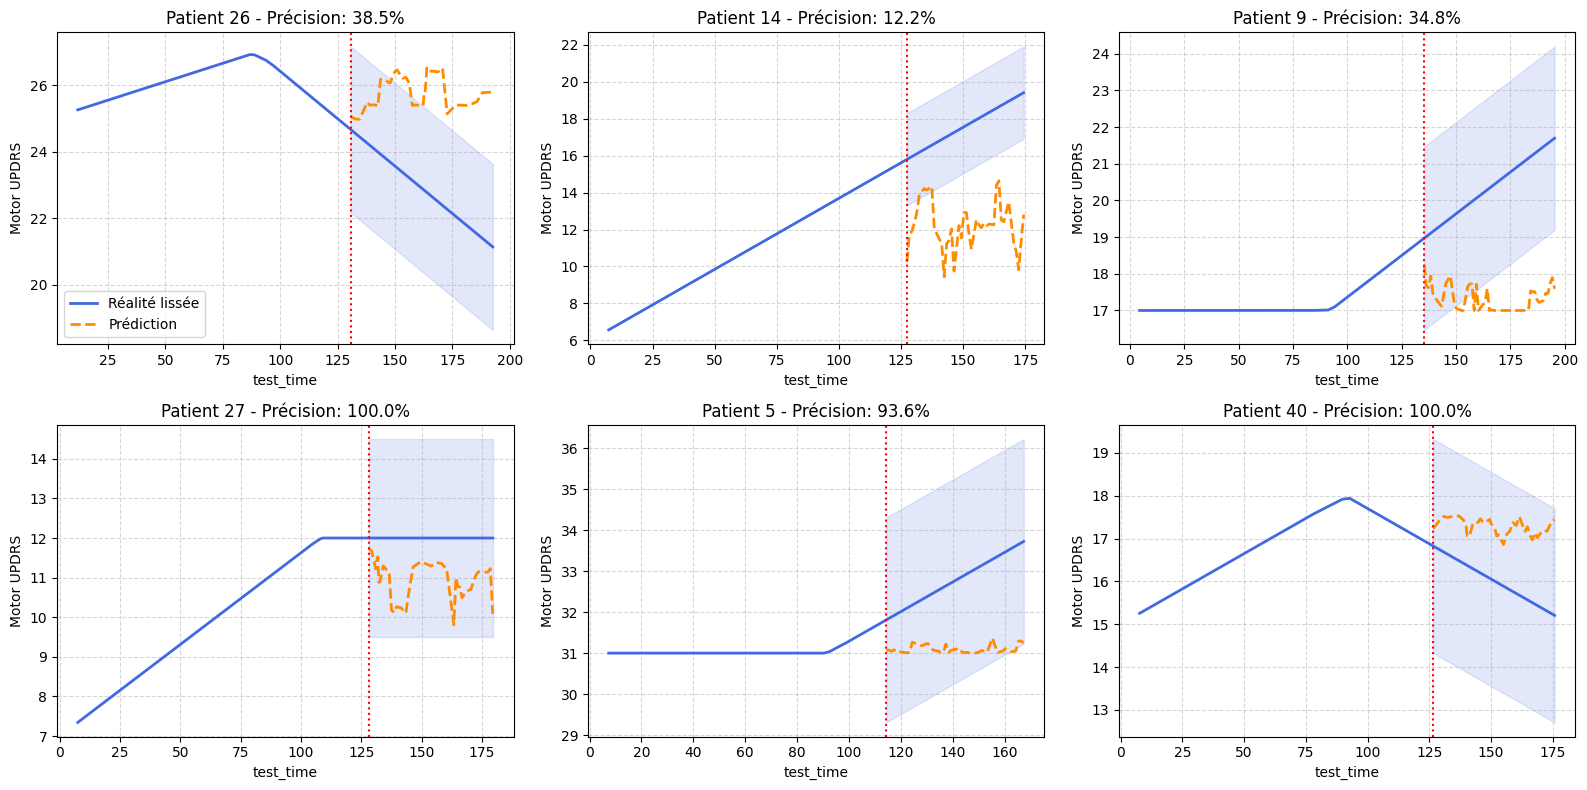

In [ ]:
# --- 0. RECRÉATION DE LA BASE DE DONNÉES ---
df_personnalise = X_features.copy()
df_personnalise['motor_UPDRS'] = y_targets['motor_UPDRS'] if isinstance(y_targets, pd.DataFrame) else y_targets
df_personnalise['patient_id'] = groups

# Définition des colonnes à exclure de l'entraînement
cols_to_drop = ['motor_UPDRS', 'patient_id', 'test_time', 'age', 'sex']
marge = 2.5 # Marge de tolérance clinique

# Récupération de tous les IDs patients uniques
tous_les_patients = df_personnalise['patient_id'].unique()

# Sélection de 6 patients au hasard (fixation du seed pour reproductibilité)
np.random.seed(42)
patients_aleatoires = np.random.choice(tous_les_patients, size=6, replace=False)

# Préparation de la figure globale (2 lignes, 3 colonnes)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
axes = axes.flatten()

for i, patient_id in enumerate(patients_aleatoires):
    # 1. Extraction et tri des données du patient
    patient_data = df_personnalise[df_personnalise['patient_id'] == patient_id].copy()
    patient_data = patient_data.sort_values(by='test_time')

    # 2. Lissage sur 7 jours
    cols_numeriques = patient_data.select_dtypes(include=[np.number]).columns
    patient_data[cols_numeriques] = patient_data[cols_numeriques].rolling(window=7, min_periods=1).mean()

    # 3. Séparation 70/30
    split_index = int(len(patient_data) * 0.7)
    train_p = patient_data.iloc[:split_index]
    test_p = patient_data.iloc[split_index:]

    X_train_s = train_p.drop(columns=[c for c in cols_to_drop if c in train_p.columns], errors='ignore')
    y_train_s = train_p['motor_UPDRS']

    X_test_s = test_p.drop(columns=[c for c in cols_to_drop if c in test_p.columns], errors='ignore')
    y_test_s = test_p['motor_UPDRS']

    # 4. Entraînement et prédiction
    rf_smooth = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
    rf_smooth.fit(X_train_s, y_train_s)
    y_pred_s = rf_smooth.predict(X_test_s)

    # 5. Calcul de la précision clinique
    erreurs_absolues = np.abs(y_test_s - y_pred_s)
    precision = np.mean(erreurs_absolues <= marge) * 100

    # 6. Tracé sur le sous-graphique correspondant
    ax = axes[i]
    ax.plot(patient_data['test_time'], patient_data['motor_UPDRS'], label='Réalité lissée', color='royalblue', linewidth=2)
    ax.plot(test_p['test_time'], y_pred_s, label='Prédiction', color='darkorange', linestyle='--', linewidth=2)
    ax.fill_between(test_p['test_time'], y_test_s - marge, y_test_s + marge, color='royalblue', alpha=0.15)
    ax.axvline(x=test_p['test_time'].iloc[0], color='red', linestyle=':')

    ax.set_title(f'Patient {patient_id} - Précision: {precision:.1f}%')
    ax.set_xlabel('test_time')
    ax.set_ylabel('Motor UPDRS')
    ax.grid(True, linestyle='--', alpha=0.5)

    if i == 0:
        ax.legend()

plt.tight_layout()
plt.show()

**Interprétation :**

Notons que les scores réels n'étant mesurés que lors des visites espacées de plusieurs mois, les lignes droites observées sur le graphique ne sont que des interpolations et non le véritable état quotidient du patient.

Le modèle génère des estimations fluctuantes car il réagit aux variations quotidiennes de la voix. Les scores élevés s'expliquent par la faible évolution de la cible sur ces périodes. Les prédictions aléatoirs tombent alors par chanche dans la marge de tolérance.

###4.3.2 Classification binaire

In [ ]:
# 1. Préparation et tri chronologique
df_classif = X_features.copy()
# On cible le total_UPDRS comme tu l'as suggéré
df_classif['total_UPDRS'] = y_targets['total_UPDRS'] if isinstance(y_targets, pd.DataFrame) else y_targets
df_classif['patient_id'] = groups

df_classif = df_classif.sort_values(by=['patient_id', 'test_time'])

# 2. Calcul de l'évolution en points par rapport au premier jour (baseline)
baselines = df_classif.groupby('patient_id')['total_UPDRS'].transform('first')
df_classif['evolution_points'] = df_classif['total_UPDRS'] - baselines

# 3. Création des 4 classes
def attribuer_classe(evolution):
    if evolution < 2.0:
        return 0  # Stagnation avec marge d'erreur
    else:
        return 1  # Aggravation

df_classif['classe_evolution'] = df_classif['evolution_points'].apply(attribuer_classe)

print("Répartition des classes (en %) :")
print(df_classif['classe_evolution'].value_counts(normalize=True) * 100)

# 4. Séparation sans fuite de données
cols_to_drop = ['total_UPDRS', 'patient_id', 'test_time', 'age', 'sex', 'evolution_points', 'classe_evolution']
X_c = df_classif.drop(columns=[c for c in cols_to_drop if c in df_classif.columns], errors='ignore')
y_c = df_classif['classe_evolution']
groups_c = df_classif['patient_id']

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X_c, y_c, groups_c))

X_train_c, X_test_c = X_c.iloc[train_idx], X_c.iloc[test_idx]
y_train_c, y_test_c = y_c.iloc[train_idx], y_c.iloc[test_idx]

# 5. Entraînement d'un classifieur de base (avec pondération pour déséquilibre)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_classifier.fit(X_train_c, y_train_c)

# 6. Évaluation sur les patients inconnus
y_pred_c = rf_classifier.predict(X_test_c)

print("\n=== RAPPORT DE CLASSIFICATION (Sur les patients de test) ===")
print(classification_report(y_test_c, y_pred_c, target_names=['Stagnation', 'Aggravation']))

Répartition des classes (en %) :
classe_evolution
0    53.412766
1    46.587234
Name: proportion, dtype: float64

=== RAPPORT DE CLASSIFICATION (Sur les patients de test) ===
              precision    recall  f1-score   support

  Stagnation       0.63      0.69      0.66       772
 Aggravation       0.39      0.33      0.36       463

    accuracy                           0.56      1235
   macro avg       0.51      0.51      0.51      1235
weighted avg       0.54      0.56      0.55      1235



**Interprétation :**

Même en réduisant le problème à 2 classes, la précision globale remonte à 56 %. Cependant, les classes étant réparties à 53 % / 47 %, un algorithme qui prédirait totalement au hasard obtiendrait un score d'environ 50 %. Le modèle n'a donc rien appris de plus qu'un pile ou face. L'objectif médical de cet outil est de repérer la dégradation du patient. Or, le score *F1* pour la classe "Aggravation" stagne à 0.36. Le modèle est incapable d'isoler la signature vocale d'une aggravation clinique.

Nous noterons qu'il n'est pas nécessaire de tester une régression logistique ou d'autres classifieurs car le résultat serait le même. Le problème ne vient pas de la complexité du modèle, mais du fait de la qualité des engeristrements vocaux.


### 4.3.3 Forecasting

=== ÉVALUATION CLINIQUE PAR PATIENT (Ensemble du jeu de test) ===
 Patient_ID  Score_Initial  Score_90_jours  Vrai_Score_6_mois  Score_Prédit_6_mois  Erreur_Absolue
          9           23.1            25.0               26.4                 23.9             2.5
         42           28.6            35.9               32.5                 35.9             3.4
         41           37.2            44.8               43.4                 39.5             3.8
         14           10.6            16.7               24.8                 33.4             8.6
         26           30.7            34.5               26.5                 37.8            11.3
         31           29.8            35.0               25.8                 37.3            11.6
         27           11.3            14.9               18.4                 34.0            15.6
         20           18.4            16.6               16.8                 34.0            17.2
          5           39.2            42.0 

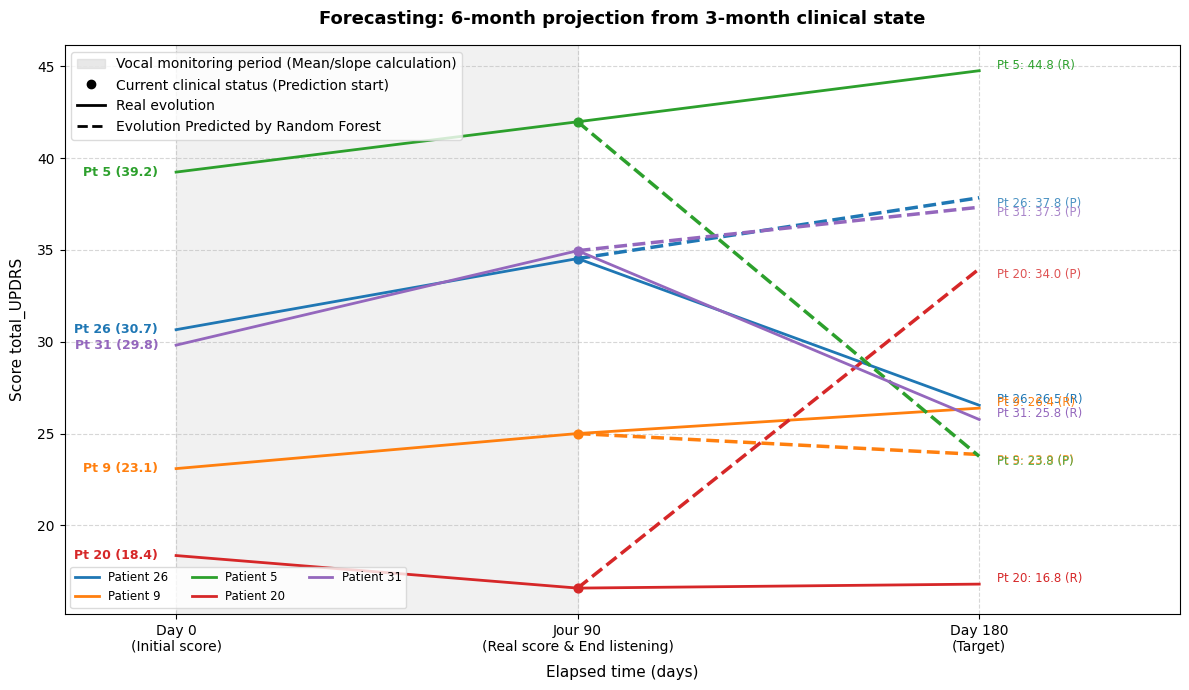

In [ ]:
warnings.filterwarnings('ignore')

# --- 0. RECRÉATION DE LA BASE DE DONNÉES (API UCI) ---
from ucimlrepo import fetch_ucirepo

datas_pks = fetch_ucirepo(id=189)
X_features = datas_pks.data.features
y_targets = datas_pks.data.targets
patient_ids = datas_pks.data.ids

df_combined = pd.concat([X_features, y_targets], axis=1)
df_combined['patient_id'] = patient_ids.values

# --- 1. RECONSTRUCTION DU PROFIL PATIENT (FORECASTING) ---
cols_to_drop = ['motor_UPDRS', 'total_UPDRS', 'patient_id', 'test_time', 'age', 'sex']
colonnes_vocales = [col for col in df_combined.columns if col not in cols_to_drop]

X_patients, y_patients, ids_patients, baseline_patients, score_90_patients = [], [], [], [], []

for pid in df_combined['patient_id'].unique():
    p_data = df_combined[df_combined['patient_id'] == pid].sort_values('test_time')
    t_start = p_data['test_time'].min()

    # Fenêtre d'observation vocale (0 à 90 jours)
    obs_data = p_data[(p_data['test_time'] >= t_start) & (p_data['test_time'] <= t_start + 90)]
    target_data = p_data[p_data['test_time'] >= t_start + 160]

    if not obs_data.empty and not target_data.empty:
        score_initial = obs_data.iloc[0]['total_UPDRS']
        score_90 = obs_data.iloc[-1]['total_UPDRS'] # Vrai score à la fin de la période d'écoute
        score_a_6_mois = target_data.iloc[0]['total_UPDRS']

        profil = {'age': p_data['age'].iloc[0], 'sex': p_data['sex'].iloc[0]}

        for col in colonnes_vocales:
            profil[f'{col}_moyenne'] = obs_data[col].mean()
            profil[f'{col}_variance'] = obs_data[col].std()
            pente = np.polyfit(obs_data['test_time'], obs_data[col], 1)[0] if len(obs_data) > 1 else 0.0
            profil[f'{col}_pente'] = pente

        X_patients.append(profil)
        y_patients.append(score_a_6_mois)
        ids_patients.append(pid)
        baseline_patients.append(score_initial)
        score_90_patients.append(score_90)

X_final = pd.DataFrame(X_patients)
y_final = pd.Series(y_patients)

# --- 2. SÉPARATION ET ENTRAÎNEMENT ---
X_train_f, X_test_f, y_train_f, y_test_f, id_train, id_test, base_train, base_test, s90_train, s90_test = train_test_split(
    X_final, y_final, ids_patients, baseline_patients, score_90_patients, test_size=0.2, random_state=42
)

rf_forecaster = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_forecaster.fit(X_train_f, y_train_f)
y_pred_f = rf_forecaster.predict(X_test_f)

# --- 3. ÉVALUATION CLINIQUE COMPLETE ---
resultats_patients = pd.DataFrame({
    'Patient_ID': id_test,
    'Score_Initial': base_test,
    'Score_90_jours': s90_test,
    'Vrai_Score_6_mois': y_test_f.values,
    'Score_Prédit_6_mois': y_pred_f
})
resultats_patients['Erreur_Absolue'] = np.abs(resultats_patients['Vrai_Score_6_mois'] - resultats_patients['Score_Prédit_6_mois'])

print("=== ÉVALUATION CLINIQUE PAR PATIENT (Ensemble du jeu de test) ===")
print(resultats_patients.round(1).sort_values(by='Erreur_Absolue').to_string(index=False))

# --- 4. GÉNÉRATION DU GRAPHIQUE ÉPURÉ (1 PATIENT SUR 2) ---
plt.figure(figsize=(12, 7), dpi=100)

# Zone grisée pour matérialiser les 3 mois d'observation de la voix
plt.axvspan(0, 90, color='lightgray', alpha=0.3, zorder=0)

resultats_affiches = resultats_patients.iloc[::2].copy()

cmap = plt.get_cmap('tab10')
patients_uniques = resultats_affiches['Patient_ID'].unique()
couleurs = {pid: cmap(i % 10) for i, pid in enumerate(patients_uniques)}

for idx, row in resultats_affiches.iterrows():
    pid = int(row['Patient_ID'])
    col = couleurs[pid]

    initial = row['Score_Initial']
    score_90 = row['Score_90_jours']
    reel_6m = row['Vrai_Score_6_mois']
    pred_6m = row['Score_Prédit_6_mois']

    # 1. Trajectoire Réelle (Jour 0 -> Jour 90 -> Jour 180)
    plt.plot([0, 90], [initial, score_90], color=col, linestyle='-', linewidth=2)
    plt.plot([90, 180], [score_90, reel_6m], color=col, linestyle='-', linewidth=2)

    # 2. Trajectoire Prédite (Démarre du vrai score au jour 90 -> Prédiction au jour 180)
    plt.plot([90, 180], [score_90, pred_6m], color=col, linestyle='--', linewidth=2.5)

    # Point d'ancrage visuel à 90 jours (moment de la prédiction)
    plt.scatter([90], [score_90], color=col, s=40, zorder=3)

    # Annotations
    plt.text(-4, initial, f"Pt {pid} ({initial:.1f})", color=col, ha='right', va='center', fontsize=9, fontweight='bold')
    plt.text(184, reel_6m + 0.3, f"Pt {pid}: {reel_6m:.1f} (R)", color=col, ha='left', va='center', fontsize=8.5)
    plt.text(184, pred_6m - 0.3, f"Pt {pid}: {pred_6m:.1f} (P)", color=col, ha='left', va='center', fontsize=8.5, alpha=0.8)

plt.title("Forecasting: 6-month projection from 3-month clinical state", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Elapsed time (days)", fontsize=11, labelpad=8)
plt.ylabel("Score total_UPDRS", fontsize=11, labelpad=8)
plt.xlim(-25, 225)
plt.xticks([0, 90, 180], ['Day 0\n(Initial score)', 'Jour 90\n(Real score & End listening)', 'Day 180\n(Target)'], fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# Légendes
custom_lines = [
    mpatches.Patch(color='lightgray', alpha=0.5, label="Vocal monitoring period (Mean/slope calculation)"),
    Line2D([0], [0], marker='o', color='black', markerfacecolor='black', markersize=6, linestyle='', label='Current clinical status (Prediction start)'),
    Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='Real evolution'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Evolution Predicted by Random Forest')
]
leg1 = plt.legend(handles=custom_lines, loc='upper left', frameon=True, facecolor='white', edgecolor='lightgray')

handles_patients = [Line2D([0], [0], color=couleurs[pid], lw=2, label=f'Patient {pid}') for pid in patients_uniques]
plt.gca().add_artist(leg1)
plt.legend(handles=handles_patients, loc='lower left', ncol=3, frameon=True, facecolor='white', edgecolor='lightgray', fontsize=8.5)

plt.tight_layout()
plt.show()

**Interprétation :**

Cette approche s'affranchit du bruit en résumant 90 jours d'observation en indicateurs dynamiques pour anticiper l'état du patient 6 mois plus tard. Le modèle montre une vraie capacité à détecter la détérioration de la maladie. Pour les patients 9, 42 et 41, il capte la bonne tendance avec une erreur modérée. Pour le patient 14, il repère correctement un profil à "forte aggravation", même s'il en surestime un peu l'ampleur.

Le défaut principal de l'algorithme se révèle face aux patients dont l'état stagne ou s'améliore légèrement. Le modèle peine à repérer ces signaux de stabilité dans la voix et a tendance à prédire systématiquement une dégradation, ce qui génère les erreurs les plus fortes.

## 4.4 Synthèse de l'approche par modèles de régression classiques

Dans cette première section d'analyse, nous avons formulé notre tâche comme un problème de régression supervisé. Notre pipeline était composé d'une standardisation des données, d'une ACP pour limiter la colinéarité des variables vocales et enfin de l'entraînement des algorithmes tels que Ridge, Random Forest ou encore XGBoost. Pour éviter la fuite de données, nous avons partitionné le dataset en assurant que les patiens de tests étaient inconnus du modèle lors de l'entrainement.

Cependant, et au vu nombre réduit de données, les résultats ont montré que les approches mises en place sont inefficaces. Les scores $R^2$ ont toujours été négatifs, cela traduit le fait que les approches mises en place sont moins performantes qu'une approche stochastique.

Cette performance s'explique notamment par le fait que les variables ne sont pas i.i.d.. En effet, dans pour mettre en place des algorithmes de machine learning, la première hypothèse à faire et que les données doivent être indépendantes et identiquements distribuées. Or, nous avons vu dès les premiers graphiques que ce n'est pas le cas. En tentant de prédire le score de sévérité de la maladie pour un patient, les algorithmes mis en place vont finir par converger vers la moyenne du dataset en générant des erreurs de l'ordre de l'écart type.

# 5 La modélisation par modèles à effets mixtes

## 5.1 Introduction

Pour faire face à l'échec de prédiction de la première méthode, nous allons changer notre raisonnement pour redéfinir le cadre d'évaluation et l'architecture du modèle. Alors que nous voulions prédire l'évolution de la maladie pour un patient inconnu, il s'avère davantage faisable de prédire l'évolution de la maladie pour un patient déjà connu. L'idée est donc de cacher le score UPDRS du dernier rendez-vous pour le laisser prédire au modèle.

Pour ce faire, nous avons utilisé une architecture capable de prendre en compte les tendances globales (en faisant la moyenne des caractéristiques) et les déviations propres à chaque individu (les effets aléatoires). Nous avons ainsi basculé vers un modèle dit "à effets mixtes".

Cela nous amène à une nouvelle problématique : L'analyse de l'évolution des signaux vocaux d'un patient par rapport à son évaluation initiale permet-elle de modéliser et de prédire l'aggravation de sa pathologie dans le temps ?

## 5.2 Prétraitement et sélection des variables

Pour s'adapter au nouveau modèle, nous avons traité les données de façon différentes. Tout d'abord, nous avons appliqué une transformation logarithmique sur la *target* `total_UPDRS` pour stabiliser la variance et améliorer l'interprétabiltié des données. Enfin, au lieu d'utiliser l'ACP, nous avons utilisé un filtrage LASSO. Il permet notamment de gérer la forte colinéarité entres les différents marqueurs vocaux. LASSO contraint les coefficients des variables redondantes à 0.



In [ ]:
df_full = X_features.copy()
df_full['total_UPDRS'] = y_targets['total_UPDRS']
df_full['patient_id'] = patient_ids.values.flatten()

# Log transformation
df_full['log_total_UPDRS'] = np.log(df_full['total_UPDRS'])

# Sort the dataset
df_full = df_full.sort_values(by=['patient_id', 'test_time']).reset_index(drop=True)

# Train / Test
# Test = the very last visit for each of the 42 patients
# Train = all previous visits
test_indices = df_full.groupby('patient_id').tail(1).index
train_df = df_full.drop(index=test_indices).copy()
test_df = df_full.loc[test_indices].copy()

print(f"Train Dimensions: {train_df.shape}")
print(f"Test Dimensions : {test_df.shape}")

# Standardization of predictors
features_retenues = ['age', 'test_time', 'HNR']
scaler = StandardScaler()

train_df[features_retenues] = scaler.fit_transform(train_df[features_retenues])
test_df[features_retenues] = scaler.transform(test_df[features_retenues])

Train Dimensions: (5833, 22)
Test Dimensions : (42, 22)


## 5.3 Le modèle linaire à effet mixtes (LMM)

Dans la littérature, un modèle mixte s'écrit généralement $Y_{ij} = X_{ij}^T\beta + Z_{ij}^Tu_i + \epsilon_{ij}$.
Ici, nous appliquons cette structure à notre dataset en regroupant les termes de population (effets fixes) et les déviations individuelles (effets aléatoires) :

$$ \log(UPDRS_{ij}) = \underbrace{(\beta_0 + b_{0i})}_{\text{Niveau initial}} + \underbrace{(\beta_1 + b_{1i})}_{\text{Vitesse}} test\_time_{ij} + \beta_2 age_i + \beta_3 HNR_{ij} + \beta_4 (test\_time_{ij} \times HNR_{ij}) + \epsilon_{ij} $$


Pour que notre modèle converge via la méthode REML (Restricted Maximum Likelihood), il faut formuler des hypothèses :
1. **Variance inter-patient (Effets aléatoires) :** Le vecteur des effets aléatoires du patient $i$, $b_i = (b_{0i}, b_{1i})^T$, suit une loi normale multivariée $\mathcal{N}(0, \Sigma)$. La matrice de covariance $\Sigma$ modélise l'hétérogénéité de la cohorte.
2. **Variance intra-patient (Bruit) :** Les résidus $\epsilon_{ij} \sim \mathcal{N}(0, \sigma^2)$ sont supposés i.i.d. Ils capturent les fluctuations locales de la voix indépendantes de la maladie.

Pour la vulgarisation de ce modèle, nous vous conseillons la vidéo suivante :
[Simplistics (QuantPsych), 24 juillet 2024](https://youtu.be/5tOifM51ZOk?si=SDauYTFqaxFphf-Y)

(https://youtu.be/5tOifM51ZOk?si=SDauYTFqaxFphf-Y)

In [ ]:
# Utility function for prediction with Fixed Effects + Random Effects
def predict_mixed_model(fitted_model, df_eval):
    # Fixed effects
    pred_fixed = fitted_model.predict(df_eval)

    # Random effects specific to each patient
    pred_random = np.zeros(len(df_eval))
    random_effects_dict = fitted_model.random_effects

    for idx, (row_idx, row) in enumerate(df_eval.iterrows()):
        pid = row['patient_id']
        if pid in random_effects_dict:
            re_patient = random_effects_dict[pid]
            b_0i = re_patient.get('Group', 0.0)          # Random Intercept
            b_1i = re_patient.get('test_time', 0.0)      # Random diretion
            pred_random[idx] = b_0i + b_1i * row['test_time']

    # Total prediction on the log scale
    pred_log = pred_fixed.values + pred_random

    # Inverse transformation to the original clinical scale of total_UPDRS
    pred_original_scale = np.exp(pred_log)
    return pred_original_scale

# LMM training
lmm_model = smf.mixedlm(
    formula="log_total_UPDRS ~ age + test_time * HNR",
    data=train_df,
    groups=train_df["patient_id"],
    re_formula="~test_time"
)

# Restricted Maximum Likelihood
lmm_result = lmm_model.fit(reml=True, method="lbfgs")
print("LMM summary")
print(lmm_result.summary())

# Evaluation of the LMM on the test set (last 42 visits)
y_test_true = test_df['total_UPDRS'].values
y_pred_lmm = predict_mixed_model(lmm_result, test_df)

mse_lmm = mean_squared_error(y_test_true, y_pred_lmm)
rmse_lmm = np.sqrt(mse_lmm)
mae_lmm = mean_absolute_error(y_test_true, y_pred_lmm)

print(f"\n LMM Test Performance (original scale):")
print(f"MSE : {mse_lmm:.2f}")
print(f"RMSE: {rmse_lmm:.2f}")
print(f"MAE : {mae_lmm:.2f}")

LMM summary
             Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  log_total_UPDRS
No. Observations:  5833     Method:              REML           
No. Groups:        42       Scale:               0.0038         
Min. group size:   100      Log-Likelihood:      7682.6959      
Max. group size:   167      Converged:           Yes            
Mean group size:   138.9                                        
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              3.275    0.062 52.766 0.000  3.153  3.397
age                    0.142    0.060  2.384 0.017  0.025  0.260
test_time              0.037    0.014  2.679 0.007  0.010  0.064
HNR                    0.004    0.001  2.750 0.006  0.001  0.006
test_time:HNR         -0.008    0.001 -6.345 0.000 -0.011 -0.006
Group Var              0.16

/tmp/ipykernel_632/2975974478.py:34: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  lmm_result = lmm_model.fit(reml=True, method="lbfgs")


## 5.4 Le modèle additif généralisé à effets mixtes (GAMM)

Comme nous l'avons vu dans la section 2, les trajectoires ne sont pas linéaires. Un modèle linéaire ne peut donc pas représenter précisément les trajectoires patients. De ce fait, nous avons mis en place un GAMM. Contrairement au LMM qui impose une pente droite, le GAMM remplace l'effet linéaire du temps par une fonction de lissage $f(test\_time)$.

Dans notre implémentation `smf.mixedlm`, nous utilisons l'argument `cr(test_time, df=6)`. Mathématiquement, cela signifie que $f$ est approchée par une combinaison linéaire de $k=6$ fonctions de base (des splines cubiques de régression) :
$$ f(test\_time_{ij}) = \sum_{k=1}^6 c_k B_k(test\_time_{ij}) $$

Le modèle estime les coefficients $c_k$ tout en appliquant une pénalité sur la courbure pour éviter le surapprentissage. On a donc :
$$ \log(UPDRS_{ij}) = \beta_0 + \beta_1 age_i + \beta_2 HNR_{ij} + \sum_{k=1}^6 c_k B_k(test\_time_{ij}) + b_{0i} + b_{1i} test\_time_{ij} + \epsilon_{ij} $$
Cela permet de capter les phases d'accélération ou de stagnation de la maladie, tout en conservant l'effet aléatoire $b_{1i}$ pour isoler la vitesse propre au patient $i$.

In [ ]:
gamm_model = smf.mixedlm(
    formula="log_total_UPDRS ~ age + HNR + cr(test_time, df=6)",
    data=train_df,
    groups=train_df["patient_id"],
    re_formula="~test_time"
)

gamm_result = gamm_model.fit(reml=True, method="lbfgs")
print("GAMM summary")
print(gamm_result.summary())

# GAMM evaluation on the test set (last 42 visits)
y_pred_gamm = predict_mixed_model(gamm_result, test_df)

mse_gamm = mean_squared_error(y_test_true, y_pred_gamm)
rmse_gamm = np.sqrt(mse_gamm)
mae_gamm = mean_absolute_error(y_test_true, y_pred_gamm)

print(f"\nGAMM Performance Test (original scale):")
print(f"MSE : {mse_gamm:.2f}")
print(f"RMSE: {rmse_gamm:.2f}")
print(f"MAE : {mae_gamm:.2f}")

GAMM summary
             Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  log_total_UPDRS
No. Observations:  5833     Method:              REML           
No. Groups:        42       Scale:               0.0037         
Min. group size:   100      Log-Likelihood:      7714.3543      
Max. group size:   167      Converged:           No             
Mean group size:   138.9                                        
----------------------------------------------------------------
                       Coef.  Std.Err.   z   P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept               3.883                                   
age                     0.143    0.060 2.397 0.017  0.026  0.259
HNR                     0.004    0.001 3.257 0.001  0.002  0.007
cr(test_time, df=6)[0] -0.694                                   
cr(test_time, df=6)[1] -0.659                                   
cr(test_time, df=6)[2] -0.

/usr/local/lib/python3.13/dist-packages/statsmodels/regression/mixed_linear_model.py:2384: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  rslt = super().fit(
/tmp/ipykernel_632/2982672866.py:10: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  gamm_result = gamm_model.fit(reml=True, method="lbfgs")
/tmp/ipykernel_632/2982672866.py:10: ConvergenceWarning: Gradient optimization failed, |grad| = 0.196180
  gamm_result = gamm_model.fit(reml=True, method="lbfgs")
/tmp/ipykernel_632/2982672866.py:10: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  gamm_result = gamm_model.fit(reml=True, method="lbfgs")
/usr/local/lib/python3.13/dist-packages/statsmodels/regression/mixed_linear_model.py:2947: RuntimeWarning: invalid value encountered in sqrt
  sdf[0 : self.k_fe, 1] = np.sqrt(np.diag(self.cov_params()[0 : self.k_fe]))


## 5.5 Synthèse de l'approche par modèles à effects mixtes

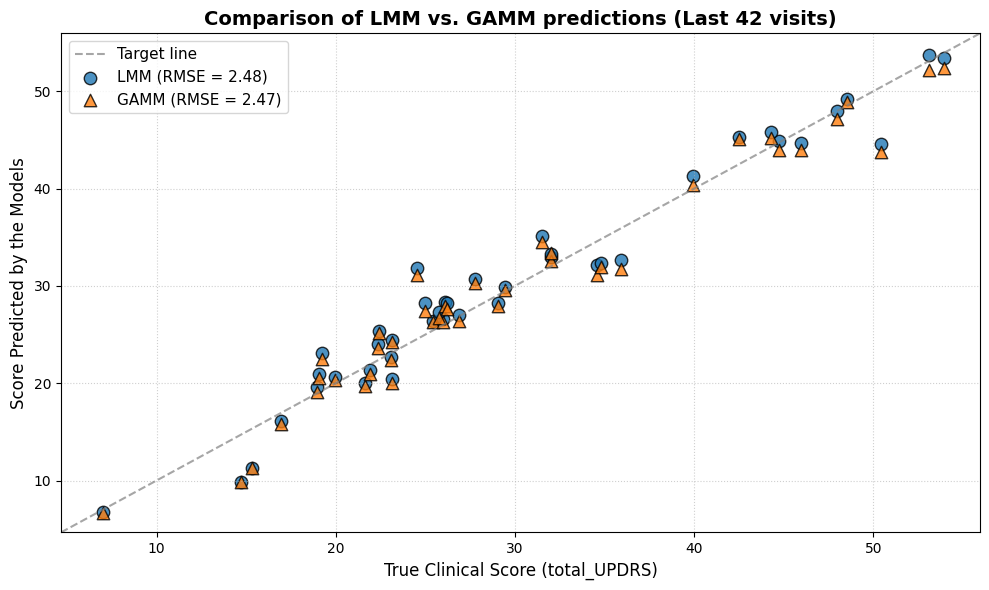

In [ ]:
plt.figure(figsize=(10, 6))

# Target line
lims = [min(y_test_true.min(), y_pred_lmm.min(), y_pred_gamm.min()) - 2,
        max(y_test_true.max(), y_pred_lmm.max(), y_pred_gamm.max()) + 2]
plt.plot(lims, lims, color='grey', linestyle='--', alpha=0.7, label='Target line')

# LMM's plot
plt.scatter(y_test_true, y_pred_lmm, color='#1f77b4', alpha=0.8, edgecolors='k', s=80, label=f'LMM (RMSE = {rmse_lmm:.2f})')

# GAMM's plot
plt.scatter(y_test_true, y_pred_gamm, color='#ff7f0e', alpha=0.8, edgecolors='k', s=80, marker='^', label=f'GAMM (RMSE = {rmse_gamm:.2f})')

# Display
plt.title('Comparison of LMM vs. GAMM predictions (Last 42 visits)', fontsize=14, fontweight='bold')
plt.xlabel('True Clinical Score (total_UPDRS)', fontsize=12)
plt.ylabel('Score Predicted by the Models', fontsize=12)
plt.xlim(lims)
plt.ylim(lims)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper left')
plt.tight_layout()
plt.show()

**Interprétation :**

Cette dernière figure évalue la capacité de généralisation des modèles mixtes. Concrètement, le modèle a été entraîné sur l'historique des premières visites  de chaque patient afin d'estimer ses effets aléatoires, puis nous avons évalué sa capacité à prolonger la courbe d'évolution pour prédire le score de la toute derni_re consultation clinique. Les cercles bleus et les triangles oranges représentent le score prédit respectivement par le LMM et le GAMM, par rapport au score clinique réel.

Nous pouvons dès lors constater que cette approche par effects mixtes est, de loin, la plus pertienente dans le cadre de ce dataset. Les prédictions s'alignent le long de la cible, cela se traduit par des erreurs quadratiques moyennes faibles. Si le modèle GAMM semble avoir des performances significativement meilleures lorsque la variable du score `score_UPDRS` augmente, cette amélioration ne justifie pas son coût calculatoire face au modèle plus simple de LMM.

Bien que ces résultats soient meilleurs que ceux des algorithmes de machine learning, nous pouvons noter quelques limites.

Tout d'abord, il est important de noter que la précision affichée ici repose sur l'inertie de la maladie et sur la connaissance préalable du patient. Le modèle ayant estimé l'*intercept* de chaque patient grâce à l'historique d'entraînement, il est très performant pour prolonger la trajectoire. Face à un nouveau patient, le modèle sera incapable d'estimer cet intercept efficacement. Il lui faudra, de la même façon, une période de calibration contenant les premières mesures cliniques. Rappelons également qu'il manque des données cruciales pour prédire efficacement et de façon cohérente l'évolution de la maladie. Notamment au travers de variables binaires expliquant les cycles de médication du patient<a href="#note3"><sup>[3]</sup></a>. Les mesures étant prises par la voix, un bruit important, propre à l'environnement du patient (fatigue, stress, bruits ambiants) fausse les résultats.

--
<p id="note3"><small>[3] : Les patients suivent des cycles de médication dopaminergique. Cela produit des effets dits "On/Off" modifiant ainsi la voix de manière transitoire.</small></p>

# 6 Conclusion

Pour conclure, les caractéristiques acoustiques de la voix permettent bien de prédire l'aggravation de la maladie de Parkinson, mais sous certaines conditions. Nous avons démontré qu'une approche classique de machine learning n'était pas performante. La forte variabilité vocale entre les patients provoque beaucoup de bruit, rendant la prédiction compliquée. La solution repose sur l'approche intra-patient. En utilisant des modèles à effets mixtes, nous avons pu isoler la baseline propre à chaque patient tout en conservant la tendance globale de la population. Au vu de l'erreur, le suivi télémédical par la voix a prouvé son utilité. En perspective, il serait intéressant de pouvoir tester ces modèles mixtes sur des patients lourdement atteints par la maladie. Ou bien, si l'IA parvient à récupérer assez de données, nous pourrions mettre en place des modèles de deep learning, ou bien des algorithmes non supervisés pour découvrir de nouveaux profils d'évolution de la maladie.

# 7 Références

*   Tsanas, A., Little, M. A., McSharry, P. E., & Ramig, Lorraine O. (2010). Accurate telemonitoring of Parkinson's disease progression by noninvasive speech tests. *IEEE Transactions on Biomedical Engineering*, *57*(4), 884–893.
*   Tong, R., Wang, L., Wang, T., & Yan, W. (2026). Modeling Parkinson’s disease progression from longitudinal voice biomarkers: A comparative study of statistical and neural mixed effects models. *Computer Methods and Programs in Biomedicine Update*, *9*, Article 100242. https://doi.org
*   Boersma, P., & Weenink, D. (2001). PRAAT, a system for doing phonetics by computer. *Glot International*, *5*, 341–345.
